In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"



# INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory 
try:
    new_dir = pathlib.Path(FIG_DIR+'/Wind_Obs/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

try:
    new_dir = pathlib.Path(FIG_DIR+'/sf_class_frequ/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

try:
    new_dir = pathlib.Path(FIG_DIR+'/KDE_observations/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass


mimi.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
# import packages
from imports import (np, plt, xr, glob, pd, BoundaryNorm, cm, sns, LinearSegmentedColormap, set_context, WindroseAxes, Wedge, Patch, Line2D, date2num, DateFormatter,)
import functions as fct



In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [6]:
particle_vars = [
        'aggregate',
        'graupel',
        'pristine'
    ]
var_names = np.concatenate((np.array(['wind_direction', 'air_temperature', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'most_common_class']), np.array(particle_vars)))


In [7]:

# Combine HATPRO 10 min averaged temperature and Airport 10 min wind data
dsx = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'10min_filled_obs_hatpro_airport_*ANX_2023*.nc'))))
# substitute the wind direction and speed and remove the variable *_filled*
dsx['wind_direction'] = dsx['wind_direction_filled'].copy()
dsx['wind_speed'] = dsx['wind_speed_filled'].copy()
dsx = dsx.drop_vars(["wind_direction_filled", "wind_speed_filled"],)



In [9]:
# for temp_bin in ['cold', 'neutral', 'warm']:
#     for wind_bin in ['N', 'NE', ..., 'NW']:
#         # Count dominant snowflake classes within this category
loc = 'HATPRO_Airport_10min'
# T = dsx['air_temperature']
# T = T[~np.isnan(T.values)]

# # Reprocess temperature categories (use e.g., 25th /75th percentile)
# q25_temp = T.quantile(q=0.25, dim='time', keep_attrs =True, skipna=True).values
# q50_temp = T.quantile(q=0.50, dim='time', keep_attrs =True, skipna=True).values
# q75_temp = T.quantile(q=0.75, dim='time', keep_attrs =True, skipna=True).values

# print(f"{loc}: Temperature 25th percentile = {q25_temp:.2f}, 50th percentile = {q50_temp:.2f}, 75th percentile ={q75_temp:.2f}")

# def temp_bin(temp):
#     if temp <= q25_temp:
#         return "cold"
#     elif temp >= q75_temp:
#         return "warm"
#     else:
#         return "neutral"

# I have each individual snowflake class as a variable in the dataset, where 1 stands for existing and where it does not exist there is a nan. How can I combine it to one variable with snowflake class?
df = dsx[['air_temperature', 'wind_direction', 'wind_speed', 'most_common_class']].to_dataframe().dropna()
df
# create a Boolean mask for the rows to remove
mask = df['most_common_class'] == ''
# select all rows except the ones that contain ''
df = df[~mask]

df



,air_temperature,wind_direction,wind_speed,most_common_class
time,,,,
2023-02-19 08:20:00,2.106073,30.0,6.7,graupel
2023-02-19 08:21:00,2.026147,20.0,4.6,aggregate
2023-02-19 08:22:00,1.802942,20.0,4.6,graupel
2023-02-19 08:23:00,1.562891,20.0,4.6,graupel
2023-02-19 08:24:00,1.312982,20.0,4.6,graupel
...,...,...,...,...
2023-03-13 01:26:00,-2.458228,210.0,4.1,aggregate
2023-03-13 01:27:00,-2.458228,210.0,4.1,aggregate
2023-03-13 01:31:00,-2.458228,190.0,5.1,graupel


In [10]:
def wind_sector(deg):
    if (deg >= 337.5) or (deg < 22.5):
        return 'N'
    elif 22.5 <= deg < 67.5:
        return 'NE'
    elif 67.5 <= deg < 112.5:
        return 'E'
    elif 112.5 <= deg < 157.5:
        return 'SE'
    elif 157.5 <= deg < 202.5:
        return 'S'
    elif 202.5 <= deg < 247.5:
        return 'SW'
    elif 247.5 <= deg < 292.5:
        return 'W'
    else:
        return 'NW'

# def wind_sector(deg):
#     if (deg >= 348.75) or (deg < 11.25):
#         return 'N'
#     elif 11.25 <= deg < 33.75:
#         return 'NNE'
#     elif 33.75 <= deg < 56.25:
#         return 'NE'
#     elif 56.25 <= deg < 78.75:
#         return 'ENE'
#     elif 78.75 <= deg < 101.25:
#         return 'E'
#     elif 101.25 <= deg < 123.75:
#         return 'ESE'
#     elif 123.75 <= deg < 146.25:
#         return 'SE'
#     elif 146.25 <= deg < 168.75:
#         return 'SSE'
#     elif 168.75 <= deg < 191.25:
#         return 'S'
#     elif 191.25 <= deg < 213.75:
#         return 'SSW'
#     elif 213.75 <= deg < 236.25:
#         return 'SW'
#     elif 236.25 <= deg < 258.75:
#         return 'WSW'
#     elif 258.75 <= deg < 281.25:
#         return 'W'
#     elif 281.25 <= deg < 303.75:
#         return 'WNW'
#     elif 303.75 <= deg < 326.25:
#         return 'NW'
#     else:
#         return 'NNW'

In [11]:
# # Step 1: Define Temperature Bins
# df['temp_cat'] = df['air_temperature'].apply(temp_bin)
# 1°C bins
temp_bins = np.arange(-6, 7, 1)
df['temp_bin'] = pd.cut(df['air_temperature'], bins=temp_bins, include_lowest=True)

# Step 2: Bin Wind Direction into 8 Compass Sectors
df['wind_direction_sector'] = df['wind_direction'].apply(wind_sector)



In [12]:
# Step 3: Compute Snowflake Frequencies per (Temp Bin × Wind Sector)
# Normalize snowflake counts within each (temp, wind) bin
# counts = df.groupby(['temp_cat', 'wind_direction_sector', 'snowflake_class']).size().reset_index(name='count')
counts = df.groupby(['wind_direction_sector', 'most_common_class']).size().reset_index(name='count')

# Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
# pivot = counts.pivot_table(index=['temp_cat', 'wind_direction_sector'], columns='snowflake_class', values='count', fill_value=0)
pivot = counts.pivot_table(index=['wind_direction_sector'], columns='most_common_class', values='count', fill_value=0)

# Normalize within each (temp_cat, wind_sector) row
pivot_norm = pivot.div(pivot.sum(axis=1), axis=0)
# Reset index for plotting
pivot_norm = pivot_norm.reset_index()


In [13]:
# ese_df = pd.DataFrame(data=[{'wind_direction_sector':'ESE',
#                               'aggregate':np.nan,
#                               'graupel':np.nan,
#                               'pristine':np.nan}],
#                        columns=['wind_direction_sector',
#                                 'aggregate','graupel','pristine'])

# pivot_norm = pd.concat([pivot_norm, ese_df], axis=0, ).reset_index(drop=True)#ignore_index=True)

In [14]:
# Set index to wind direction sector
pivot_plot = pivot_norm.set_index('wind_direction_sector').T  # Transpose to have snowflake class on Y-axis
# Optional: Reorder compass directions
ordered_sectors = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
# ordered_sectors = ['N', 'NNE','NE', 'ENE', 'E', 'ESE','SE', 'SSE','S','SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

pivot_plot = pivot_plot[ordered_sectors]


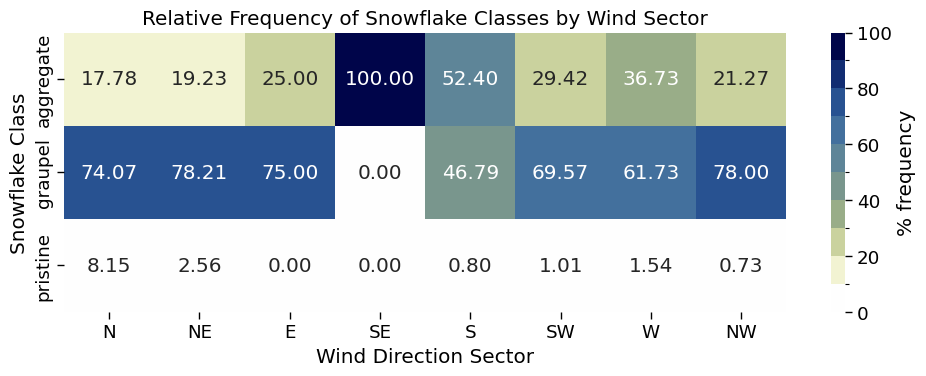

In [15]:
# Create the heatmap
# cmap = cm.hawaii_r
cmap = cm.davos_r
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0,1*100, 11)
# Create a custom colormap
cmap = LinearSegmentedColormap.from_list('Custom cmap', cmaplist, cmap.N)
norm = BoundaryNorm(bounds, 10)


plt.figure(figsize=(10, 4))
# plt.figure(figsize=(15,4))
ax = sns.heatmap(pivot_plot * 100, annot=True, fmt=".2f", cmap=cmap.resampled(10), norm=norm, cbar_kws={'label': '% frequency'})

# Labeling
ax.set_ylabel("Snowflake Class")
ax.set_xlabel("Wind Direction Sector")
ax.set_title("Relative Frequency of Snowflake Classes by Wind Sector")

plt.tight_layout()

# figname = f"sf_class_frequ/sf_class_frequency_by_WD.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [202]:
# Plot rose diagrams of wind direction by snowflake class

# hatpro_airport = fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed',], mask=None)

data_dict = {
    'aggregate': fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed', ], mask=(dsx['most_common_class'] =='aggregate')),
    'graupel':   fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed', ], mask=(dsx['most_common_class'] =='graupel')),
    'pristine':   fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed', ], mask=(dsx['most_common_class'] =='pristine'))
}



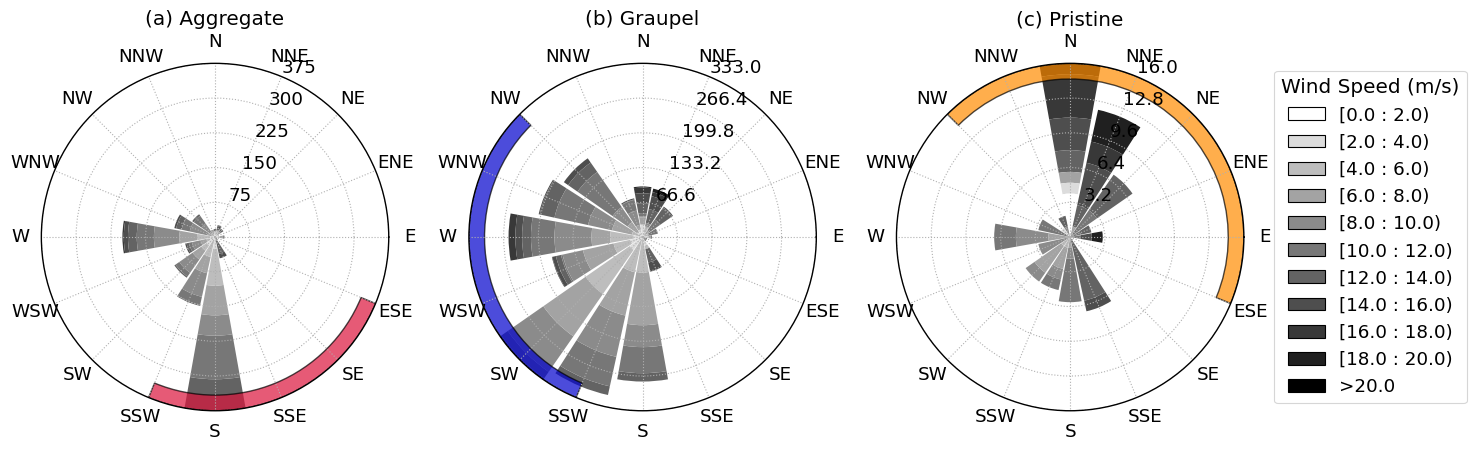

In [203]:
fig, axsm = plt.subplots(1,3, figsize=(15,6), subplot_kw=dict(projection="windrose"))


# Create a windrose axes object

direction_labels = ['E',  'ENE',  'NE', 'NNE', 'N', 'NNW', 'NW', 'WNW', 'W', 'WSW', 'SW', 'SSW', 'S', 'SSE', 'SE', 'ESE', ]

# cmap=cm.hawaii_r
cmap = cm.grayC_r
bins = np.arange(0,22,2)
normed = False

legend_labels_drawn = set()


    
for (i,ax), (key, item) in zip(enumerate(axsm),data_dict.items()):
    # ax.grid(linestyle="dashed", color="grey", zorder=0)

    ax.bar(item['wind_direction'], item['wind_speed'], bins=bins, normed=normed, cmap=cmap, edgecolor=None, opening=0.9)
    # Customize the plot
    ax.set_thetagrids(np.arange(0, 360, 22.5), labels=direction_labels)
    # # ax.set_yticklabels('')
    # ax.set_yticks([5, 10, 15, 20, 25, 30, 35])
    # ax.set_yticklabels(['5%', '10%', '15%', '20%', '25%', '30%', '35%'])
    ax.grid(True, ls=':')
    ax.set_title(f"{fct.fig_label[i]} {key.capitalize()}")
    # ax.text(0.05, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)  
    
_wedge = Wedge(center=(0.5, 0.5), r=0.5, width=0.045, theta1=fct.met_to_math_deg(202.5), theta2=fct.met_to_math_deg(112.5),
                    facecolor='crimson', alpha=0.7, edgecolor='black',linewidth=1, transform=axsm[0].transAxes, )
axsm[0].add_patch(_wedge)

_wedge = Wedge(center=(0.5, 0.5), r=0.5, width=0.045, theta1=fct.met_to_math_deg(315), theta2=fct.met_to_math_deg(202.5),
                    facecolor='mediumblue', alpha=0.7, edgecolor='black',linewidth=1, transform=axsm[1].transAxes, )
axsm[1].add_patch(_wedge)

_wedge = Wedge(center=(0.5, 0.5), r=0.5, width=0.045, theta1=fct.met_to_math_deg(112.5), theta2=fct.met_to_math_deg(315),
                    facecolor='darkorange', alpha=0.7, edgecolor='black',linewidth=1, transform=axsm[2].transAxes, )
axsm[2].add_patch(_wedge)

axsm[-1].legend(loc='center left', title='Wind Speed (m/s)', bbox_to_anchor=(1.06, 0.5))

plt.tight_layout()

# figname = f"Wind_Obs/windrose_HATPRO_Airport_10min_aggregate_graupel_pristine.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [204]:
vals = dsx['most_common_class']
agg_times = vals.where(dsx['most_common_class'] == 'aggregate')
agg_times = agg_times.dropna('time')['time']


In [205]:
graup_times = vals.where(dsx['most_common_class'] == 'graupel')
graup_times = graup_times.dropna('time')['time']

pris_times = vals.where(dsx['most_common_class'] == 'pristine')
pris_times = pris_times.dropna('time')['time']

In [206]:
agg_wd = dsx['wind_direction'].sel(time=agg_times)
graupel_wd = dsx['wind_direction'].sel(time=graup_times)
pris_wd = dsx['wind_direction'].sel(time=pris_times)

In [207]:
df = pd.DataFrame({
    'wind_direction': np.concatenate([agg_wd.values, graupel_wd.values, pris_wd]),
    'type': ['aggregate'] * len(agg_wd) + ['graupel'] * len(graupel_wd) + ['pristine'] * len(pris_wd)
})

In [208]:
# Bin wind directions
# bins = np.arange(0,361,22.5)
# df['wd_bin'] = pd.cut(df['wind_direction'], bins=bins, include_lowest=True, right=False)

# Bin edges in degrees, 22.5° width
bin_edges = np.arange(-11.25, 371.25, 22.5)  # Start at -11.25 to center N on 0°
directions = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
              'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
df['compass'] = pd.cut(df['wind_direction'], bins=bin_edges, labels = directions, include_lowest=True)

In [219]:
# Count occurences per bin
count_df = df.groupby(['compass', 'type']).size().unstack(fill_value=0)
count_df = count_df.reindex(directions, fill_value= 0)

# Extract counts
pristine = count_df.get('pristine', pd.Series(0, index=directions))
aggregate = count_df.get('aggregate', pd.Series(0, index=directions))
graupel = count_df.get('graupel', pd.Series(0, index=directions))


In [218]:
count_df

type,aggregate,graupel,pristine
compass,,,
E,20,18,3
ENE,2,30,2
NE,22,71,7
NNE,26,95,12
N,3,21,8
NNW,16,76,2
NW,60,184,1
WNW,90,204,3
W,200,257,7


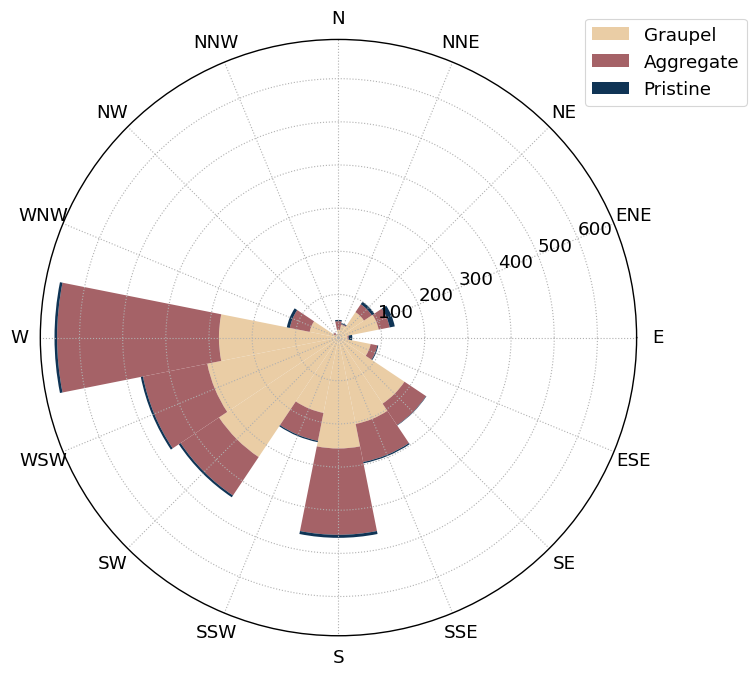

In [228]:
# Plot the windrose with aggregate/graupel ratio
# use the midpoints of the bins for angles
# angles = [interval.mid for interval in grouped['wd_bin']]
angles = np.deg2rad(np.arange(0, 360, 22.5))
width = np.deg2rad(22.5)
# ratios = grouped['ratio'].fillna(0)



fig, ax = plt.subplots(figsize=(8,7), subplot_kw=dict(polar=True))
# plot stacked bars: first graupel, then aggregate on top
bars1 = ax.bar(angles, graupel, width=width, bottom=0, color = cm.lipari(0.9), edgecolor=None, label='Graupel')
bars2 = ax.bar(angles, aggregate, width=width, bottom=graupel, color = cm.lipari(0.5), edgecolor=None, label='Aggregate')
bars1 = ax.bar(angles, pristine, width=width, bottom=aggregate+graupel, color = cm.lipari(0.1), edgecolor=None, label='Pristine')
# sm = plt.cm.ScalarMappable(cmap=cm.lipari, norm=norm)
# sm.set_array([])  # Only needed for older matplotlib
# cbar = plt.colorbar(sm, ax=ax, pad=0.1)
# cbar.set_label("Aggregate / (Aggregate+Graupel) Ratio")

# ax.set_theta_zero_location('N')
# ax.set_theta_direction(-1)
# ax.set_xticks(angles)
# ax.set_yticklabels([])  # Optional: remove radial labels
# ax.set_title("Aggregate to Graupel Ratio per Wind Direction", pad=20)
ax.set_thetagrids(np.arange(0, 360, 22.5), labels=direction_labels)
ax.grid(True, ls=':')
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.05))
plt.tight_layout()

figname = f"Wind_Obs/winddirection_aggregate_graupel_pristine_1min.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [18]:
# Count occurences
# Step 3: Compute Snowflake Frequencies per (Temp Bin × Wind Sector)
# Normalize snowflake counts within each (temp, wind) bin
counts = df.groupby(['temp_bin', 'wind_direction_sector', 'most_common_class']).size().reset_index(name='count')

# Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
pivot = counts.pivot_table(index=['temp_bin', 'wind_direction_sector'], columns='most_common_class', values='count', fill_value=0)

# Normalize within each (temp_cat, wind_sector) row
pivot_norm = pivot.div(pivot.sum(axis=1), axis=0)
# Reset index for plotting
pivot_norm = pivot_norm.reset_index()


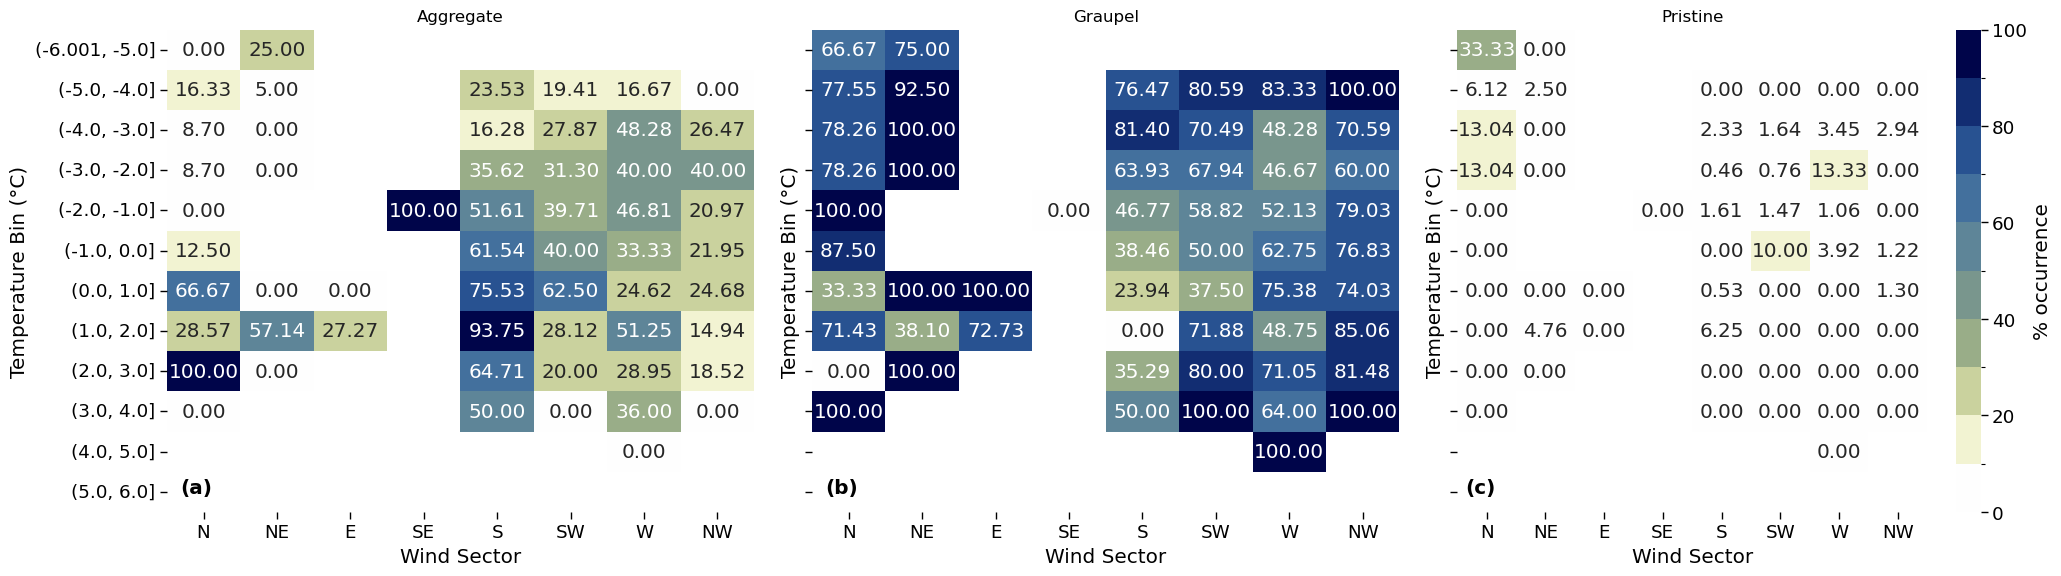

In [19]:
cmap = cm.davos_r
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0,1*100, 11)
# Create a custom colormap
cmap = LinearSegmentedColormap.from_list('Custom cmap', cmaplist, cmap.N)
norm = BoundaryNorm(bounds, 10)


# Snowflake classes to include
n = len(particle_vars)

# Get all temp_bins and wind sectors in consistent order
temp_labels = pivot_norm['temp_bin'].unique().tolist()
wind_sectors = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']

# Setup plot
fig, axs = plt.subplots(1, n, figsize=(7 * n, 6), sharey=True)

for i, cls in enumerate(particle_vars):
    ax = axs[i]

    # Pivot again: temp_bin (Y) × wind_sector (X)
    df_plot = pivot_norm.pivot(index='temp_bin', columns='wind_direction_sector', values=cls,)
    
    # Reorder axes
    df_plot = df_plot.reindex(columns=wind_sectors)
    df_plot = df_plot.reindex(index=temp_labels)

    # Plot heatmap
    sns.heatmap(df_plot * 100, cmap=cmap.resampled(10), norm=norm, annot=True, fmt=".2f", ax=ax,
                cbar=(i == n - 1),  # Only show colorbar on the last subplot
                cbar_kws={'label': '% occurrence'} if i == n - 1 else None)

    ax.set_title(cls.capitalize(), fontsize=12)
    ax.set_xlabel("Wind Sector")
    ax.set_ylabel("Temperature Bin (°C)")

    
    ax.text(0.05, 0.05, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

plt.tight_layout()

figname = f"sf_class_frequ/sf_class_frequency_by_WD_and_temp.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

### previous seperation into "CAO", "WAI" and "undefined" was too complicated and led to inconsistency

- the clearest signal appears, when focusing on 
  - **southerly and southeasterly wind** (dominated by aggregate)
  - **southwest to east wind** (dominated by graupel)
  - alternative 
    - **southwest and westerly wind** (dominated by graupel >60%)
    - **northwesterly to easterly wind** (dominated by graupel >70%)

- Proposed simpler categorization
  - southerly/southeasterly flow (e.g. 112.5° - 202.5°): **aggregate** dominated &rarr; call this "WAI"
  - southwesterly/northwesterly flow (e.g. 202.5° - 315°): **graupel** dominated &rarr; call this "marine" or "CAO"
  - northerly/easterly flow (e.g. 315° - 112.5°): **somewhat graupel** dominated &rarr; call this "other"
  - keep it *based on WD only*, not temperature


In [20]:
wai_wd_condition = ((dsx['wind_direction'] >= 112.5) & 
                    (dsx['wind_direction'] < 202.5)).compute()
    
cao_wd_condition = ((dsx['wind_direction'] >= 202.5) &
                      (dsx['wind_direction'] < 315)).compute()

other_wd_condition = ((dsx['wind_direction'] < 112.5) |
                      (dsx['wind_direction'] >= 315)).compute()


# Combine logical masks
cao_mask = cao_wd_condition #& cao_2t_condition
wai_mask = wai_wd_condition #& wai_2t_condition
other_mask = other_wd_condition
    
for var in var_names:
    if var in dsx:
        dsx[var+'_marine'] = dsx[var].where(cao_mask, drop=True)
        dsx[var+'_wai'] = dsx[var].where(wai_mask, drop=True)
        dsx[var+'_other'] = dsx[var].where(other_mask, drop=True)
        
        # print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}, Undef: {dsx[var+'_other'].count().values}")
        print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}")




HATPRO_Airport_10min, wind_direction, All: 42900, CAO: 18514, WAI: 13600
HATPRO_Airport_10min, air_temperature, All: 30152, CAO: 12690, WAI: 8815
HATPRO_Airport_10min, wind_speed, All: 42900, CAO: 18514, WAI: 13600
HATPRO_Airport_10min, precipitation, All: 387, CAO: 129, WAI: 138
HATPRO_Airport_10min, Ze, All: 249516, CAO: 142431, WAI: 54348
HATPRO_Airport_10min, W, All: 249516, CAO: 142431, WAI: 54348
HATPRO_Airport_10min, spectralWidth, All: 249456, CAO: 142396, WAI: 54335
HATPRO_Airport_10min, most_common_class, All: 27360, CAO: 11989, WAI: 7556


### Plot snowfall class distribution per new wind regime
- aggregate, graupel, pristine
- normalize by number of time steps per category

In [21]:
df_sf_class = dict()

df_sf_class = pd.DataFrame([], columns=['All', 'Marine', 'WAI', 'Other'], index=particle_vars)
for sf_class in particle_vars:
    df_sf_class['All'][sf_class] = float(dsx['most_common_class'].where((dsx['most_common_class'] == sf_class).compute()).count(dim='time').compute())
    df_sf_class['Marine'][sf_class] = float(dsx['most_common_class_marine'].where((dsx['most_common_class_marine'] == sf_class).compute()).count(dim='time').compute())
    df_sf_class['WAI'][sf_class] = float(dsx['most_common_class_wai'].where((dsx['most_common_class_wai'] == sf_class).compute()).count(dim='time').compute())
    df_sf_class['Other'][sf_class] = float(dsx['most_common_class_other'].where((dsx['most_common_class_other'] == sf_class).compute()).count(dim='time').compute())

# Calculate total sum of all points
df_sf_class.loc['total'] = df_sf_class.sum(axis=0)
# print(f"total occurence of Marine points {loc}: {df_sf_class.loc['total']['Marine']}, of WAI points: {df_sf_class.loc['total']['WAI']},")# of Other points: {df_sf_class.loc['total']['Other']}")

# relative frequency conditioned on the wind direction, temperature (normalized by the number of CAO/WAI points)
# Given CAO/WAI wind, what is the probability of each snowflake type?
df_sf_class['relative_marine'] = df_sf_class['Marine'] / df_sf_class.loc['total']['Marine']
df_sf_class['relative_wai'] = df_sf_class['WAI'] / df_sf_class.loc['total']['WAI']
df_sf_class['relative_other'] = df_sf_class['Other'] / df_sf_class.loc['total']['Other']

df_sf_class.reset_index(inplace=True)
df_sf_class.rename(columns={'index': 'sf_class'}, inplace=True)

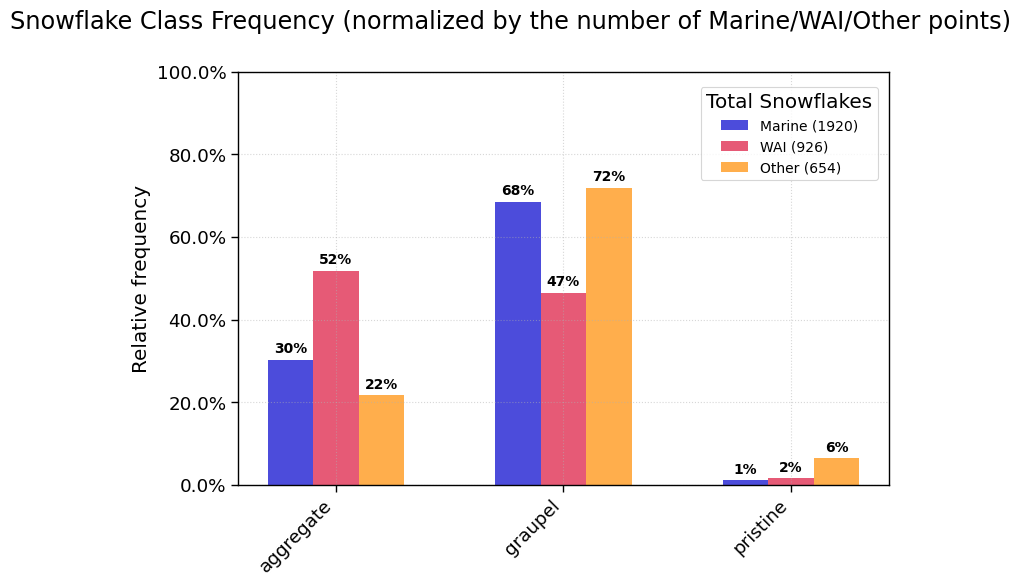

In [22]:
fig, axsm = plt.subplots(1,1, figsize=(8,6), sharex=True, sharey=True)
fig.suptitle(f"Snowflake Class Frequency (normalized by the number of Marine/WAI/Other points)", )
fig.subplots_adjust(top=0.94)
loc = 'HATPRO_Airport_10min'
# for ax, loc, i in zip(axsm.flatten(), ['HATPRO_Airport_10min'], range(len(fct.fig_label))):
# axsm.text(0.02, 0.9, f"{fct.fig_label[i]} {loc.replace('_', ' ').title()}", fontweight='bold', horizontalalignment='left', verticalalignment='center', transform=axsm.transAxes)
# Set ticks
axsm.set_yticks(np.arange(0,1.1,0.2))
axsm.set_yticklabels(f"{x:.1%}" for x in np.arange(0,1.1,0.2))
axsm.set_ylabel("Relative frequency")
axsm.set_ylim([0, 1])
axsm.set_xticks(np.arange(len(df_sf_class.index)))
axsm.set_xticklabels(df_sf_class['sf_class'], rotation=45, ha='right')
axsm.grid(alpha=0.5)

axsm.bar(df_sf_class.index[:-1]-0.2, df_sf_class['relative_marine'][:-1], width= 0.2, color='mediumblue', label=f"Marine ({df_sf_class.iloc[-1]['Marine']:.0f})", alpha=0.7)
axsm.bar(df_sf_class.index[:-1], df_sf_class['relative_wai'][:-1], width= 0.2, color='crimson', label=f"WAI ({df_sf_class.iloc[-1]['WAI']:.0f})", alpha=0.7)
axsm.bar(df_sf_class.index[:-1]+0.2, df_sf_class['relative_other'][:-1], width= 0.2, color='darkorange', label=f"Other ({df_sf_class.iloc[-1]['Other']:.0f})", alpha=0.7)

# Add text labels from the 'all' column on top of the first bar for each group
for i, val in enumerate(df_sf_class['relative_marine'][:-1]):
    axsm.text(
        i - 0.2,  # x position (adjust for bar alignment)
        max(df_sf_class.loc[i, ['relative_marine', ]]) + 0.01,  # y position above the bar
        f"{val:.0%}",  # format as integer
        ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
        )
for i, val in enumerate(df_sf_class['relative_wai'][:-1]):
    axsm.text(
        i ,  # x position (adjust for bar alignment)
        max(df_sf_class.loc[i, ['relative_wai', ]]) + 0.01,  # y position above the bar
        f"{val:.0%}",  # format as integer
        ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
        )
    
for i, val in enumerate(df_sf_class['relative_other'][:-1]):
    axsm.text(
        i + 0.2,  # x position (adjust for bar alignment)
        max(df_sf_class.loc[i, ['relative_other', ]]) + 0.01,  # y position above the bar
        f"{val:.0%}",  # format as integer
        ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
        )

axsm.legend( loc='center left',bbox_to_anchor=(0.7, 0.85), fontsize=10, frameon=True, markerscale=1.5,title="Total Snowflakes", )#title_fontsize='13', ,

axsm.grid(True, ls=':')


plt.tight_layout()

figname = f"sf_class_frequ/sf_class_frequency_marine_WAI_other.png"
# figname = f"sf_class_frequ/sf_class_frequency_marine_WAI.png"

plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

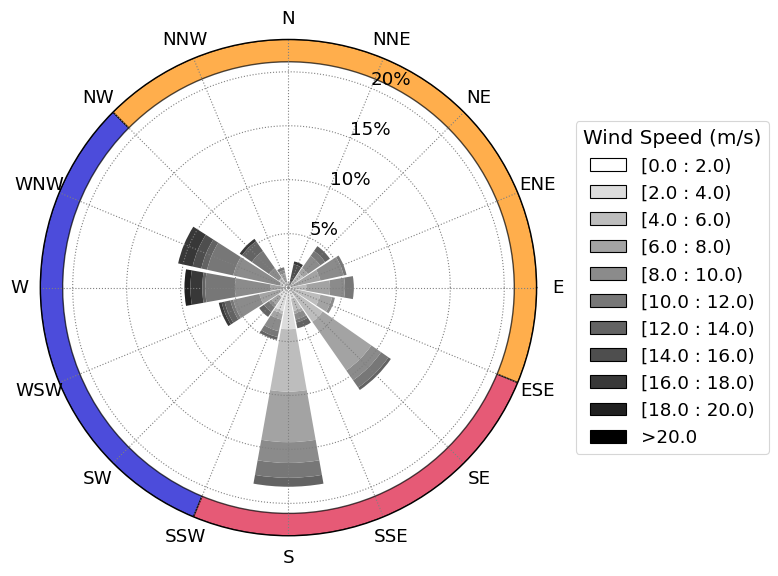

In [23]:
# hatpro_airport = fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed',], mask=None)
hatpro_airport = fct.extract_clean_data(dsx, ['wind_direction', 'wind_speed'], mask=(dsx['precipitation'] > 0.))

fig, ax = plt.subplots(1,1, figsize=(8,6), subplot_kw=dict(projection="windrose"))

# Create a windrose axes object

ax.grid(linestyle="dashed", color="grey", zorder=0)

direction_labels = ['E',  'ENE',  'NE', 'NNE', 'N', 'NNW', 'NW', 'WNW', 'W', 'WSW', 'SW', 'SSW', 'S', 'SSE', 'SE', 'ESE', ]

# cmap=cm.hawaii_r
cmap = cm.grayC_r
bins = np.arange(0,22,2)
normed = True



# --- Draw cold segment 
# --- Draw warm segments: 
segments_temp = [(202.5, 315, 'mediumblue', 'cold'),
                 (112.5, 202.5, 'crimson', 'warm'),
                 (315, 112.5, 'darkorange', 'other'),
                 ]
                #  (202.5, 360, 'mediumblue', 'cold')]
legend_labels_drawn = set()

for theta1, theta2, color, label in segments_temp:
    _wedge = Wedge(center=(0.5, 0.5), r=0.5, width=0.045, theta1=fct.met_to_math_deg(theta2), theta2=fct.met_to_math_deg(theta1),
                  facecolor=color, alpha=0.7, edgecolor='black',linewidth=1, transform=ax.transAxes, )
    ax.add_patch(_wedge)
    

    
ax.bar(hatpro_airport['wind_direction'], hatpro_airport['wind_speed'], bins=bins, normed=normed, cmap=cmap, edgecolor=None, opening=0.9)

# Customize the plot
ax.set_thetagrids(np.arange(0, 360, 22.5), labels=direction_labels)
# ax.set_yticklabels('')
ax.set_yticks([5, 10, 15, 20,])
ax.set_yticklabels(['5%', '10%', '15%', '20%', ])
ax.set_ylim([0, 23])

ax.legend(loc='center left', title='Wind Speed (m/s)', bbox_to_anchor=(1.06, 0.5))
ax.grid(True, ls=':')


plt.tight_layout()
figname = f"Wind_Obs/windrose_HATPRO_Airport_10min_marine_WAI_other.png"
# figname = f"Wind_Obs/windrose_HATPRO_Airport_10min_marine_WAI.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

### Create reflectivity - Doppler velocity plots by wind regime
- use 2D histograms / line plots of vertical profiles
- show variability across height

In [24]:
ze_bins = fct.ze_bins       # Reflectivity bins [dBZ] 1 dBZ for reflectivity
height_bins = fct.height_bins # Height bins [m] bins of 100 m for height 
H_ze_wai, H_ze_prob_wai = fct.probability_distribution(dsx, 'Ze_wai', 'height', ze_bins, height_bins,)
H_ze_marine, H_ze_prob_marine = fct.probability_distribution(dsx, 'Ze_marine', 'height', ze_bins, height_bins, )
H_ze_other, H_ze_prob_other = fct.probability_distribution(dsx, 'Ze_other', 'height', ze_bins, height_bins, )


# Doppler velocity
W_bins = fct.W_bins # bin widths of 0.075 m s−1 for Doppler velocity
H_w_wai, H_w_prob_wai = fct.probability_distribution(dsx, 'W_wai', 'height',  W_bins, height_bins,)
H_w_marine, H_w_prob_marine = fct.probability_distribution(dsx, 'W_marine', 'height', W_bins, height_bins, )
H_w_other, H_w_prob_other = fct.probability_distribution(dsx, 'W_other', 'height', W_bins, height_bins, )

# Spectral width
sW_bins = fct.sW_bins # bin widths of 0.05 m s−1 for Doppler spectral width
H_sW_wai, H_sW_prob_wai = fct.probability_distribution(dsx, 'spectralWidth_wai', 'height', sW_bins, height_bins)
H_sW_marine, H_sW_prob_marine = fct.probability_distribution(dsx, 'spectralWidth_marine', 'height', sW_bins, height_bins)
H_sW_other, H_sW_prob_other = fct.probability_distribution(dsx, 'spectralWidth_other', 'height', sW_bins, height_bins)

<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


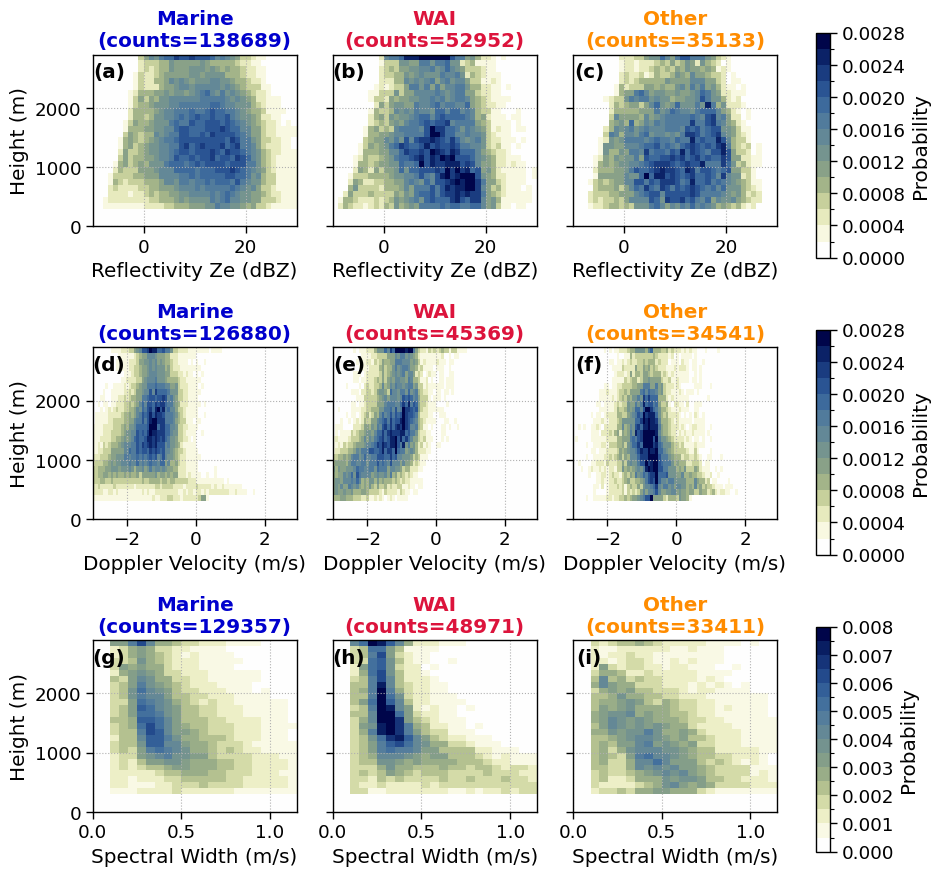

In [92]:
fig, axs = fct.plt_prob_matrix(
    height_bins,
    ze   = {'marine': H_ze_prob_marine , 'wai': H_ze_prob_wai , 'other': H_ze_prob_other},
    w    = {'marine': H_w_prob_marine  , 'wai': H_w_prob_wai  , 'other': H_w_prob_other},
    sw   = {'marine': H_sW_prob_marine , 'wai': H_sW_prob_wai , 'other': H_sW_prob_other},
    counts_ze = {'marine': H_ze_marine , 'wai': H_ze_wai , 'other': H_ze_other},
    counts_w  = {'marine': H_w_marine  , 'wai': H_w_wai  , 'other': H_w_other},
    counts_sw = {'marine': H_sW_marine , 'wai': H_sW_wai , 'other': H_sW_other},
    include_other=True,          # <── turn “other” on/off here
    # fig_size=(6, 9)
)
figname = f"sf_class_frequ/probability_Ze_W_sW_marine_WAI_other.png"
# figname = f"sf_class_frequ/probability_Ze_W_sW_marine_WAI.png"

plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

<string>:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


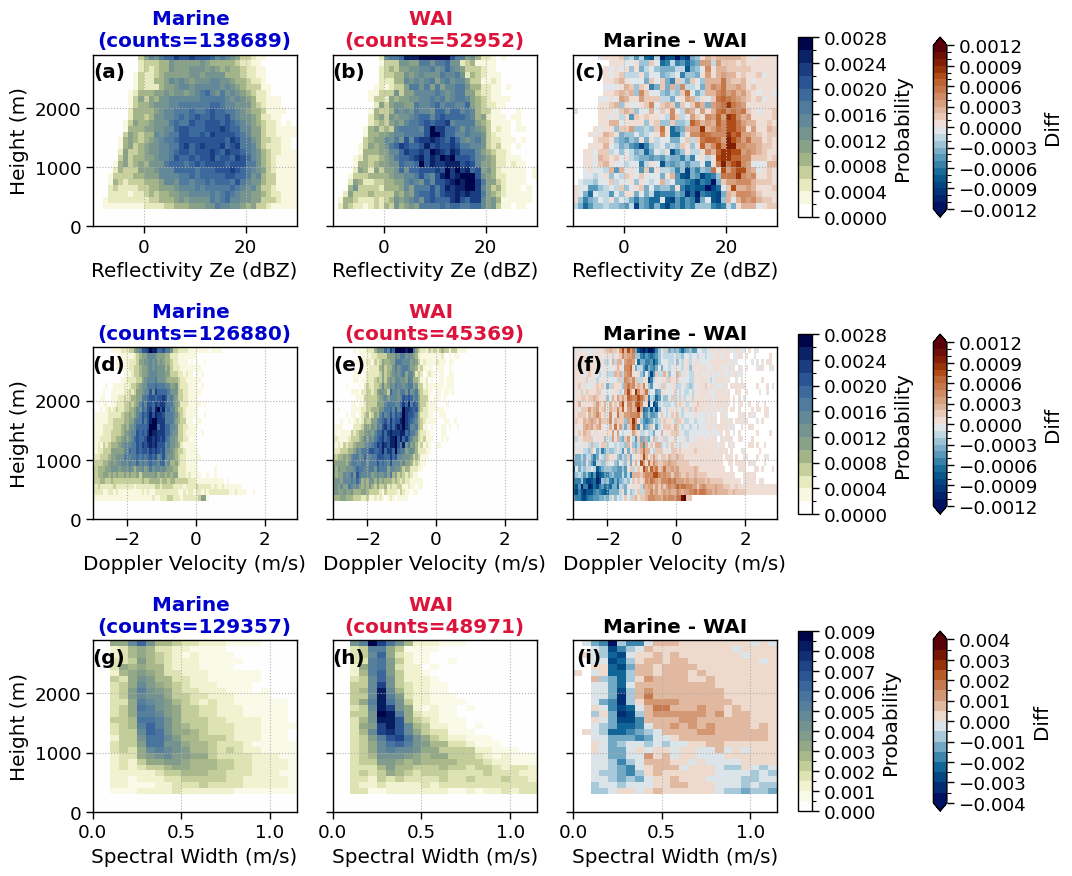

In [132]:
fig,axs = fct.plt_prob_matrix_with_diff(height_bins, 
                                     ze   = {'marine': H_ze_prob_marine , 'wai': H_ze_prob_wai , 'diff': H_ze_prob_marine - H_ze_prob_wai},
                                     w    = {'marine': H_w_prob_marine  , 'wai': H_w_prob_wai  , 'diff': H_w_prob_marine - H_w_prob_wai},
                                     sw   = {'marine': H_sW_prob_marine , 'wai': H_sW_prob_wai , 'diff': H_sW_prob_marine - H_sW_prob_wai},
                                     counts_ze = {'marine': H_ze_marine , 'wai': H_ze_wai , 'diff': 'nan'},
    counts_w  = {'marine': H_w_marine  , 'wai': H_w_wai  , 'diff': np.nan},
    counts_sw = {'marine': H_sW_marine , 'wai': H_sW_wai , 'diff': np.nan},)

figname = f"sf_class_frequ/probability_Ze_W_sW_marine_WAI_diff.png"
# figname = f"sf_class_frequ/probability_Ze_W_sW_marine_WAI.png"

plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

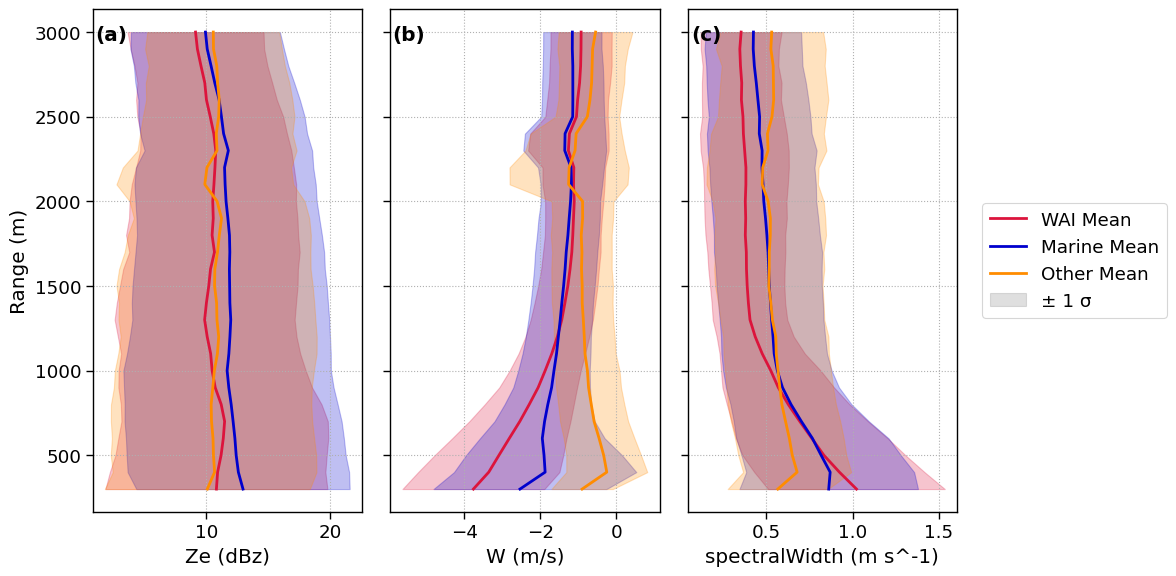

In [26]:
classes = ['WAI', 'Marine', 'Other']
colours = ['crimson', 'mediumblue', 'darkorange']
variables = ['Ze', 'W', 'spectralWidth']

fig, axsm = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
axs = axsm.flatten()

for i, variable in enumerate(variables): 
    for cls, color in zip(classes, colours):
        var = f"{variable}_{cls.lower()}"

        # 1  Compute mean & std profiles (1-D in range)
        mean = dsx[var].mean(dim='time')
        std  = dsx[var].std(dim='time')

        y = mean['range'].values                # the height / range axis
        x_mean = mean.values                    # mean Ze profile
        x_lo   = x_mean - std.values            # mean – σ
        x_hi   = x_mean + std.values            # mean + σ

        # 2  shaded ±1 σ envelope (horizontal fill, NO label)
        axs[i].fill_betweenx(
            y,                      # y-coords
            x_lo, x_hi,             # left & right bounds
            color=color, alpha=0.25, #label='±1 σ'
        )

        # 3  mean profile line (give each class its own label once)
        axs[i].plot(x_mean, y, color=color, lw=2, label=f"{cls} mean")
        
        

    # 4  cosmetics
    axs[i].set_xlabel(f'{variable} ({dsx[variable].units})')
    axs[i].set_yticks(np.arange(5, 35, 5))
    axs[i].set_yticklabels(np.arange(500, 3500, 500))
    axs[i].grid(True, ls=':')
    
    # build ONE custom legend per subplot
    line_handles = [
        Line2D([], [], color=color, lw=2, label=f"{cls} Mean") for cls, color in zip(classes, colours)
    ]
    patch_handle = Patch(facecolor='grey', alpha=0.25, edgecolor='grey', label="± 1 σ")
    
    axs[i].text(0.07, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = axs[i].transAxes)

    
axs[2].legend(handles=line_handles + [patch_handle], loc='center left', bbox_to_anchor=(1.06, 0.5))
axs[0].set_ylabel('Range (m)')


plt.tight_layout()

figname = f"sf_class_frequ/vertical_profile_Ze_W_sW_marine_WAI_other.png"
# figname = f"sf_class_frequ/vertical_profile_Ze_W_sW_marine_WAI.png"

plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


### Reflectivity vs. Doppler Velocity:


In [27]:
# Reflectivity vs Doppler velocity
ze_w_wai, ze_w_prob_wai = fct.probability_distribution(dsx, 'Ze_wai', 'W_wai', ze_bins, W_bins)
ze_w_marine, ze_w_prob_marine = fct.probability_distribution(dsx, 'Ze_marine', 'W_marine', ze_bins, W_bins)
ze_w_other, ze_w_prob_other = fct.probability_distribution(dsx, 'Ze_other', 'W_other', ze_bins, W_bins)

# Reflectivity vs. Spectral Width
ze_sw_wai, ze_sw_prob_wai = fct.probability_distribution(dsx, 'Ze_wai', 'spectralWidth_wai', ze_bins, sW_bins)
ze_sw_marine, ze_sw_prob_marine = fct.probability_distribution(dsx, 'Ze_marine', 'spectralWidth_marine', ze_bins, sW_bins)
ze_sw_other, ze_sw_prob_other = fct.probability_distribution(dsx, 'Ze_other', 'spectralWidth_other', ze_bins, sW_bins)


# Doppler velocity vs. Spectral Width
w_sw_wai, w_sw_prob_wai = fct.probability_distribution(dsx, 'W_wai', 'spectralWidth_wai', W_bins, sW_bins)
w_sw_marine, w_sw_prob_marine = fct.probability_distribution(dsx, 'W_marine', 'spectralWidth_marine', W_bins, sW_bins)
w_sw_other, w_sw_prob_other = fct.probability_distribution(dsx, 'W_other', 'spectralWidth_other', W_bins, sW_bins)

/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


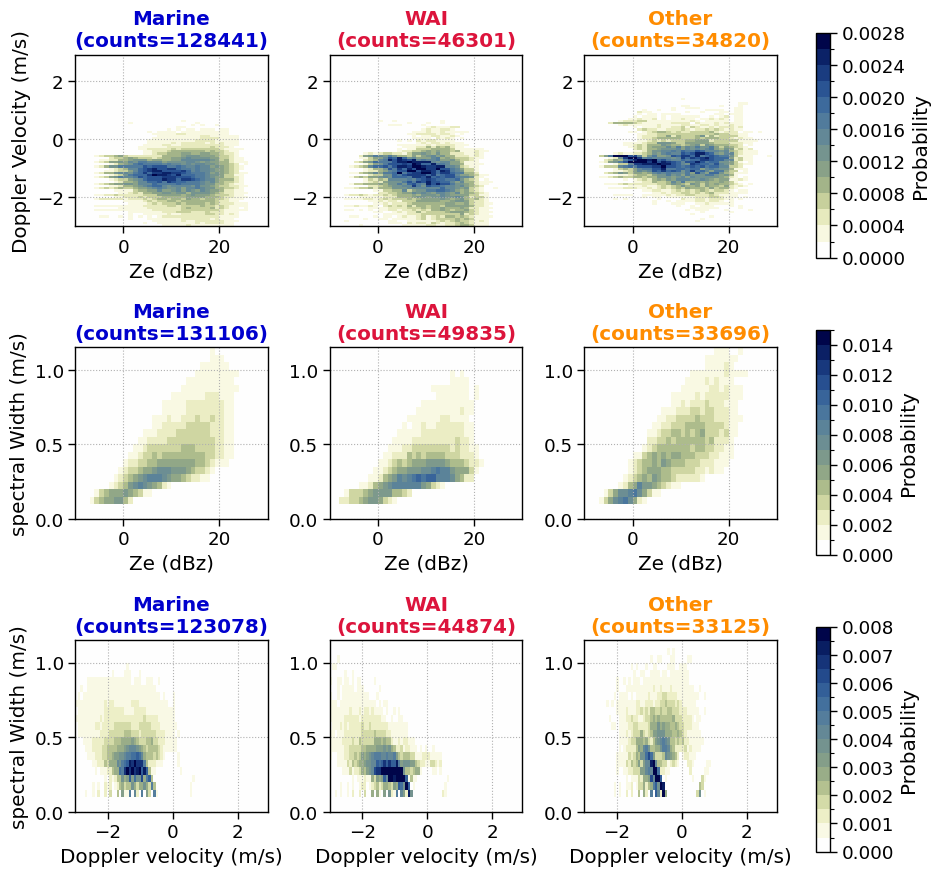

In [28]:
fig, ax = fct.plt_joint_prob_matrix(
    ze_w   = {'marine': ze_w_prob_marine , 'wai': ze_w_prob_wai , 'other': ze_w_prob_other},
    ze_sw  = {'marine': ze_sw_prob_marine  , 'wai': ze_sw_prob_wai  , 'other': ze_sw_prob_other},
    w_sw   = {'marine': w_sw_prob_marine , 'wai': w_sw_prob_wai , 'other': w_sw_prob_other},
    counts_ze_w = {'marine': ze_w_marine , 'wai': ze_w_wai , 'other': ze_w_other},
    counts_ze_sw  = {'marine': ze_sw_marine  , 'wai': ze_sw_wai  , 'other': ze_sw_other},
    counts_w_sw = {'marine': w_sw_marine , 'wai': w_sw_wai , 'other': w_sw_other},
    include_other=True,          # <── turn “other” on/off here
    # fig_size=(6, 9)
    )

figname = f"sf_class_frequ/probability_ZeW_ZeSw_WSw_marine_WAI_other.png"
# figname = f"sf_class_frequ/probability_ZeW_ZeSw_WSw_marine_WAI.png"

plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [29]:
def plt_reflectivity_for_categories(ds):

    # Colorbar layout parameters
    cbar_left = 0.92
    cbar_width = 0.015
    cbar_height = 0.4935
    cbar_top = 0.325  # starting point at the top
    cbar_step = 0.1075  # vertical space between cbar axes

   

    fig, axsm = plt.subplots(5, 1, figsize=(8.27, 11.69), sharex=True, )
    axs = axsm.flatten()

    categories = ['marine', 'wai', 'other']
    colours = {'marine': 'mediumblue', 'wai': 'crimson', 'other': 'darkorange'}
    time_vals = date2num(ds['time'].values)

    # ----- REFLECTIVITY
    # Define your radar-style reflectivity levels (can match the image closely)
    bounds  = np.array([0, 3.5, 7, 10.5, 14, 17.5, 21, 24.5, 28])
    norm= BoundaryNorm(boundaries=bounds, ncolors=256)  # hawaii_r has 256 levels
    # Use Crameri colormap (hawaii_r)
    cmap= cm.hawaii_r



    pcm = axs[0].pcolormesh(time_vals, ds['range'], ds['Ze'].transpose('range', 'time'), cmap=cmap, norm=norm, shading='auto')
    cbaxes = fig.add_axes([cbar_left, cbar_top, cbar_width, cbar_height])
    cbar = plt.colorbar(pcm, cax=cbaxes, shrink=0.5, extend='both', orientation='vertical')
    cbar.ax.set_ylabel(f"Reflectivity ({ds['Ze'].attrs['units']})")
    cbar.set_ticks(bounds)

    for ax, (i,cat) in zip(axsm.flatten()[1:], enumerate(categories)):
        pcm = ax.pcolormesh(time_vals, ds['range'], ds[f'Ze_{cat}'].transpose('range', 'time'), cmap=cmap, norm=norm, shading='auto')

    for ax in axsm.flatten()[:-1]:
        # ax.set_yticks(ds['range'][1::6])
        ax.set_yticks(np.arange(5, 35, 5))
        ax.set_yticklabels(np.arange(500, 3500, 500))
        ax.set_ylabel("Height (m)")


    # ---- 10 METER WIND
    for cat in categories:
        wd_data = ds[f'wind_direction_{cat}'][::10].dropna(dim='time')
        axs[4].scatter(wd_data['time'].values, wd_data.values, s=10, color=colours[cat], label=cat.title())
    axs[4].legend(frameon=True)
    axs[4].set_ylabel(f"Wind direction ({ds['wind_direction'].attrs['units']})",)

    ax2 = axs[4].twinx()
    ws_data = ds["wind_speed"][::10].dropna(dim='time')
    ax2.plot(ws_data['time'].values, ws_data.values, color='darkviolet')
    ax2.set_ylabel(f"Wind speed ({ds['wind_speed'].attrs['units']})", color='darkviolet')
    ax2.tick_params(axis='y', labelcolor='darkviolet')

    titles = [f"{ds['time'].dt.date[0].values}", 'Marine', 'WAI', 'Other', '10-m Wind']
    date_form = DateFormatter("%H:00")
    for ax, (i,title) in zip(axs, enumerate(titles)):
        ax.set(xlabel="", )
        ax.set_title(title, fontweight='bold') # colour argument goes here
            
        ax.xaxis.grid(True, ls=':')
        ax.tick_params(axis='x', labelrotation=0)
        plt.setp(ax.get_xticklabels(), horizontalalignment="center")
        ax.xaxis_date()
        ax.xaxis.set_major_formatter(date_form)
        ax.set_xlim([ds['time'][0], ds['time'][-1]])
        
    for ax, cat in zip(axsm.flatten()[1:-1], categories):
        ax.title.set_color(colours[cat])
        


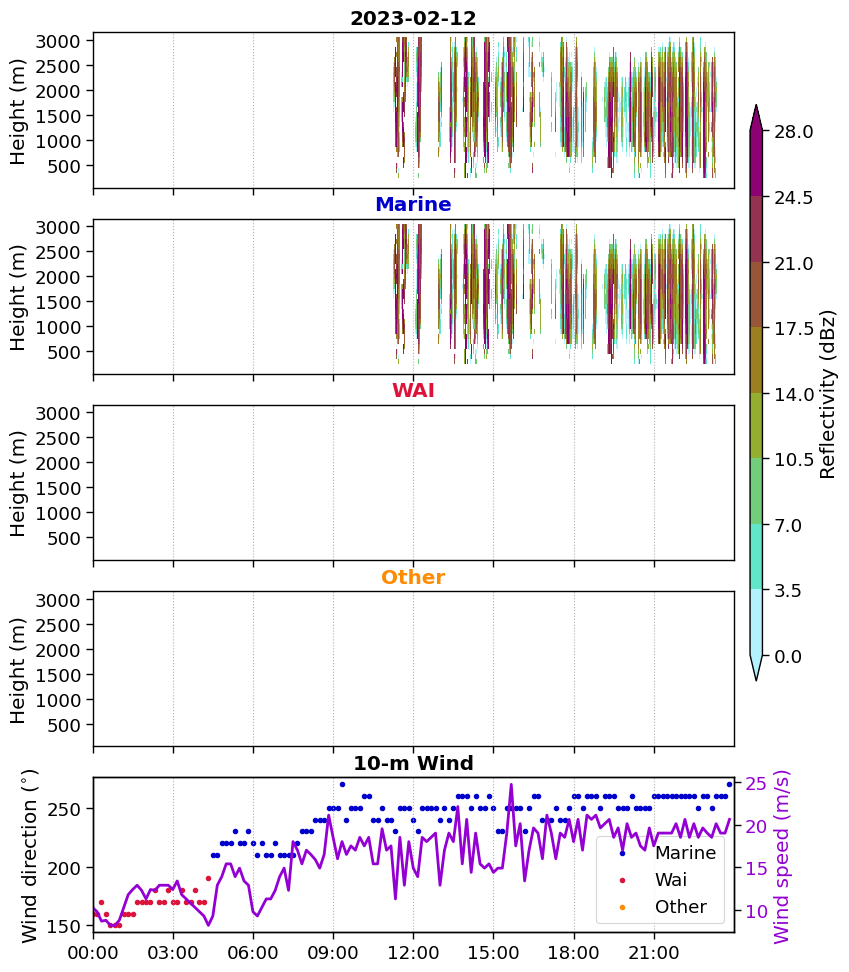

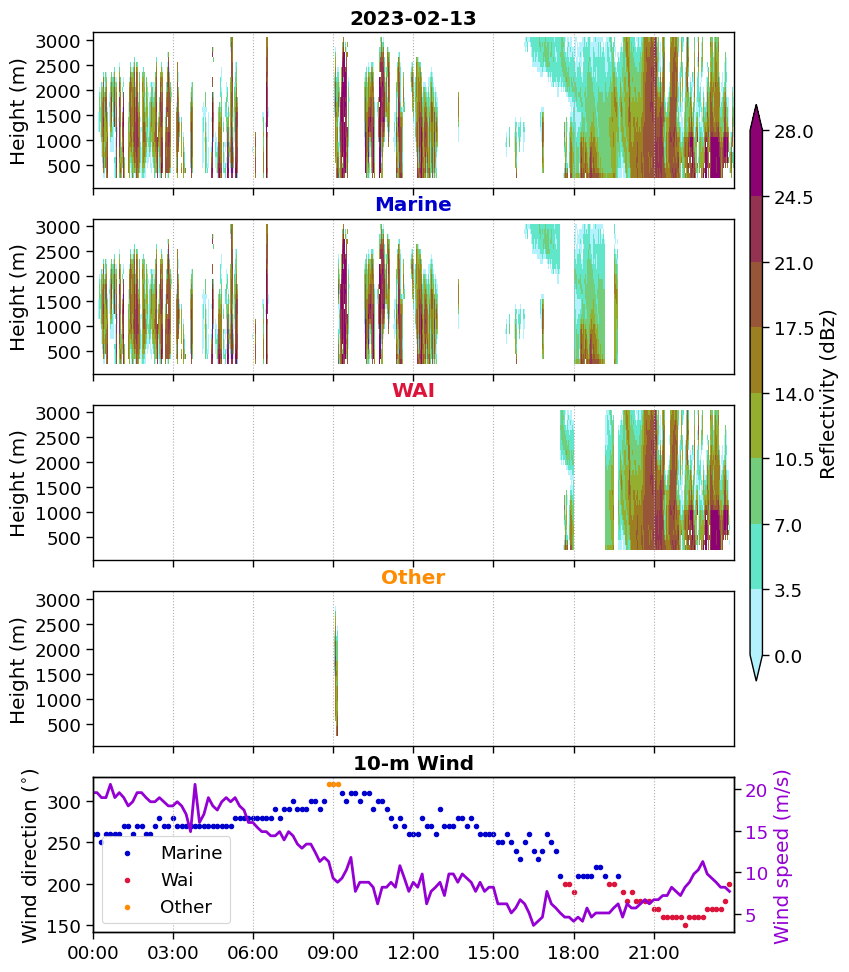

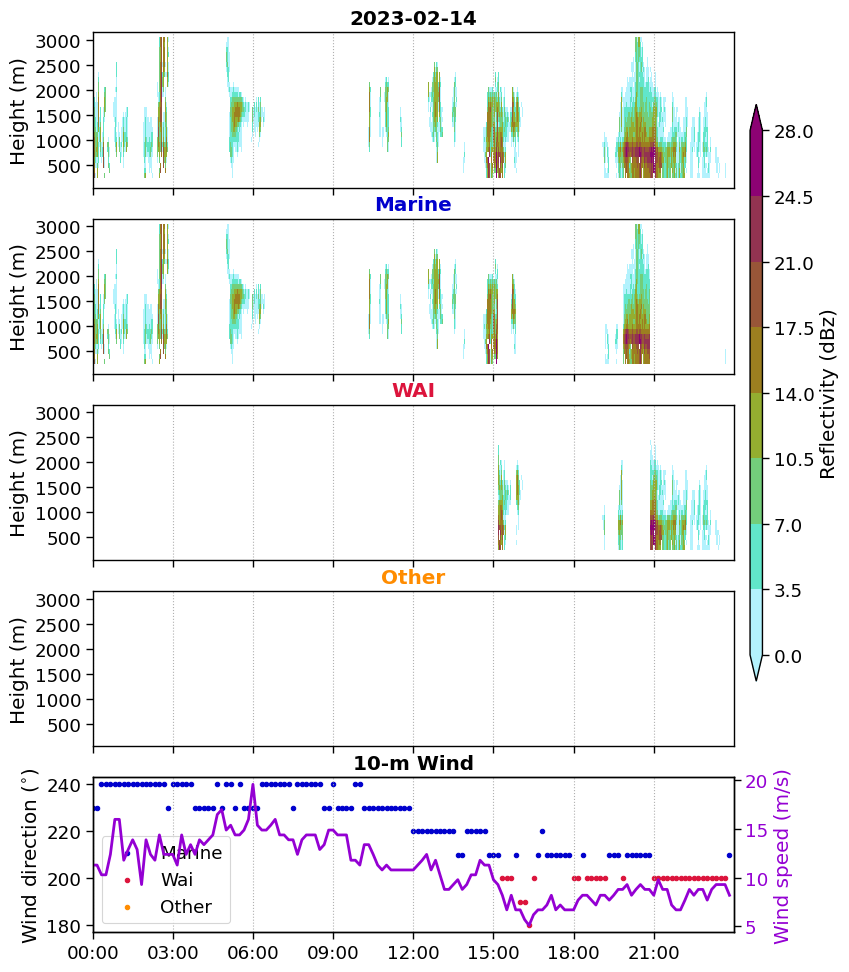

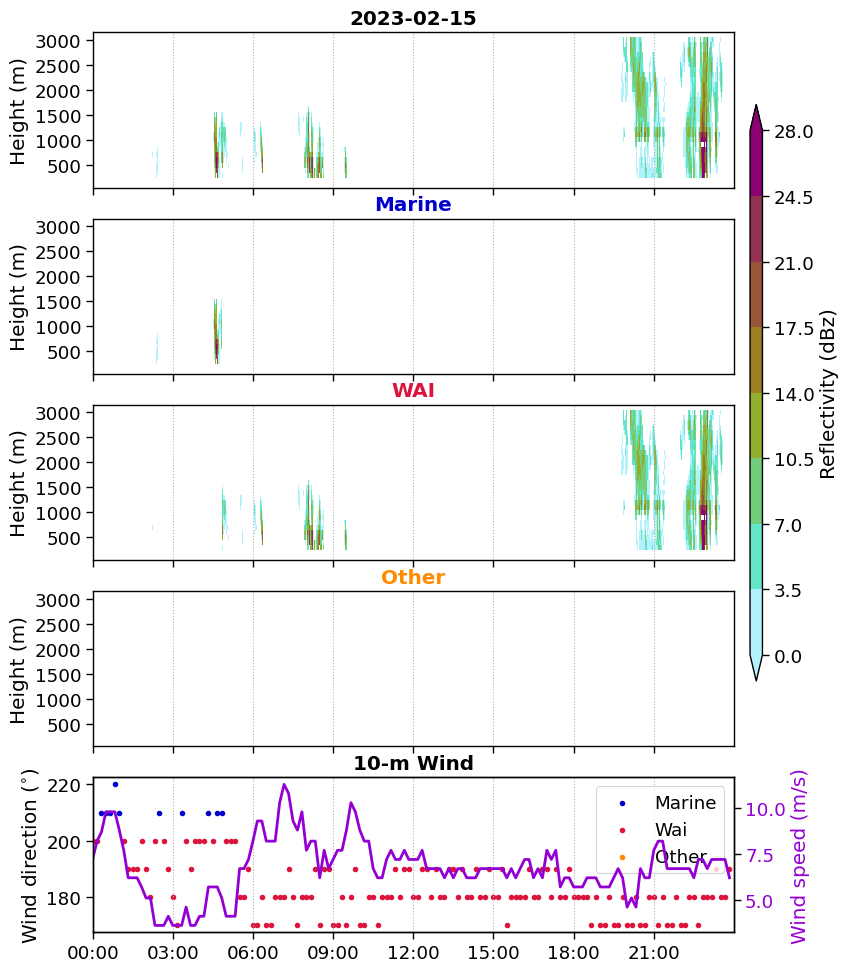

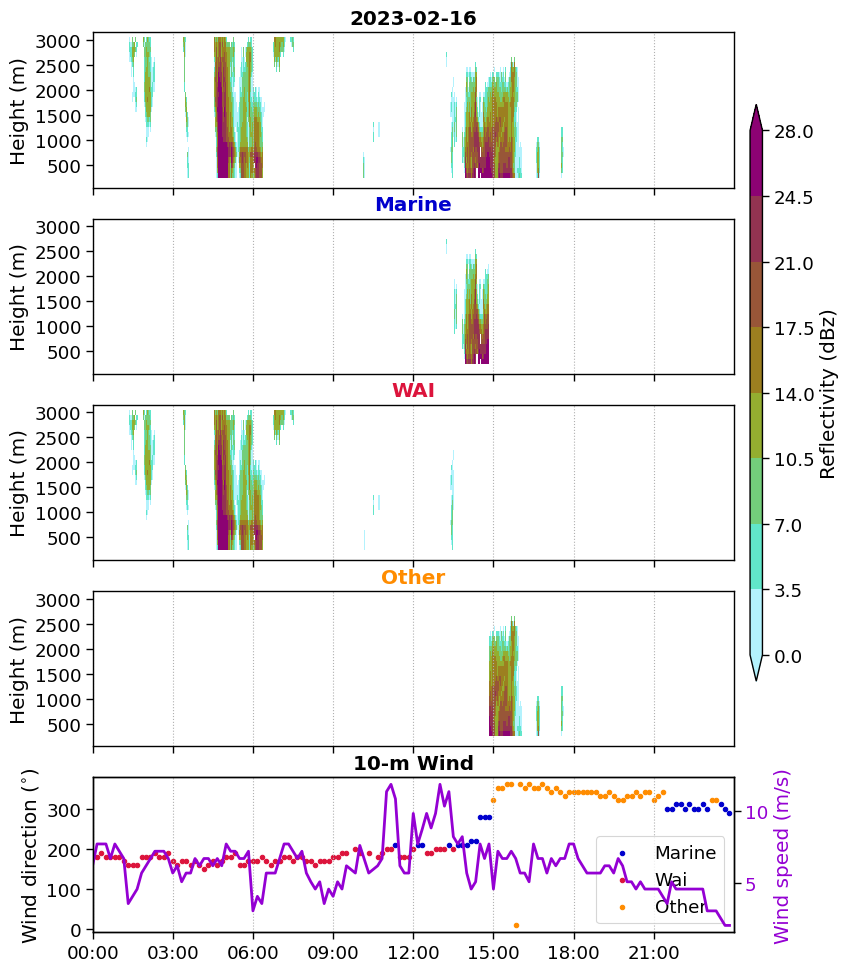

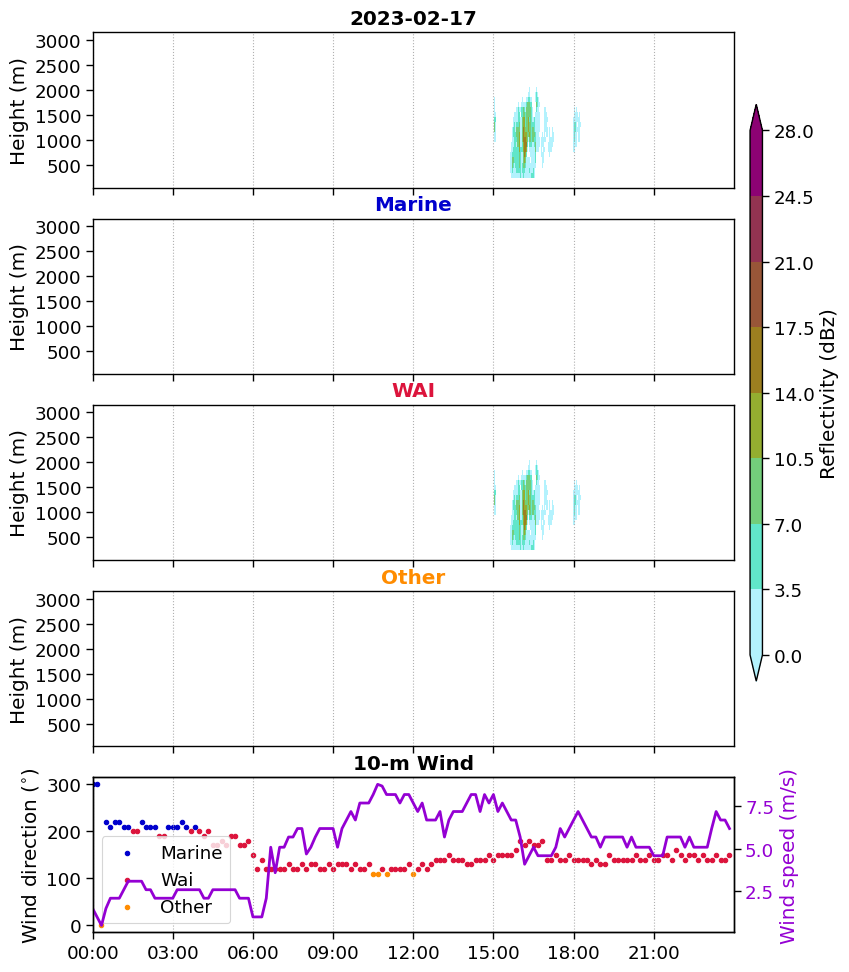

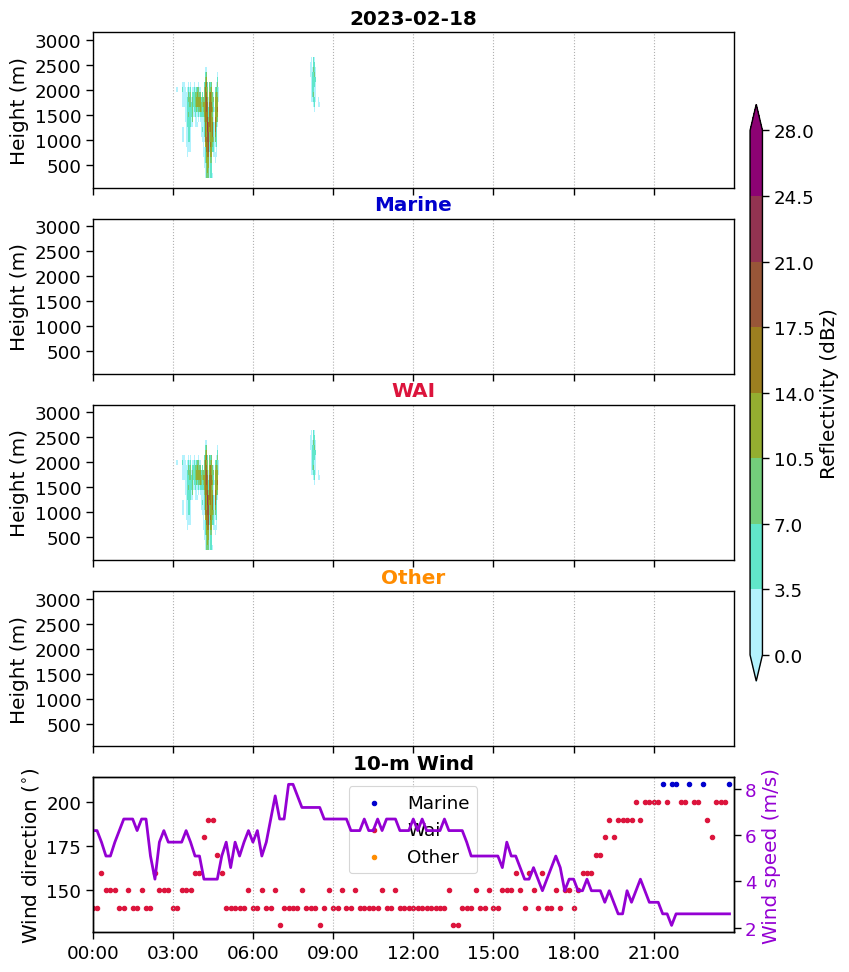

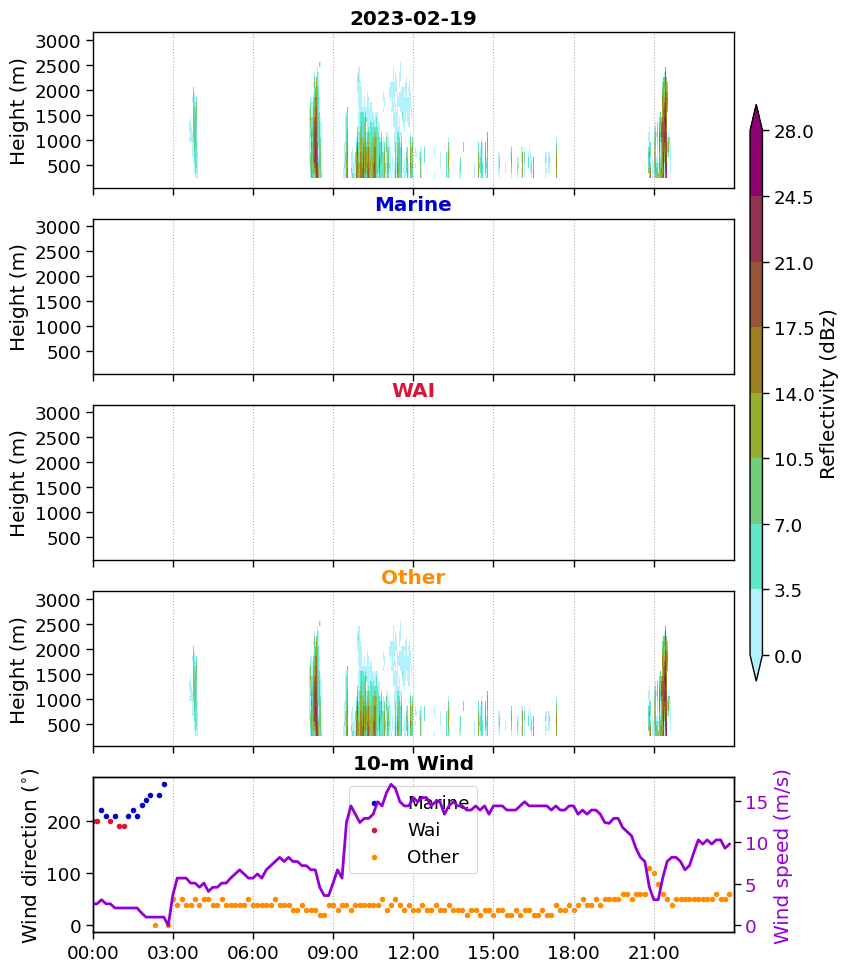

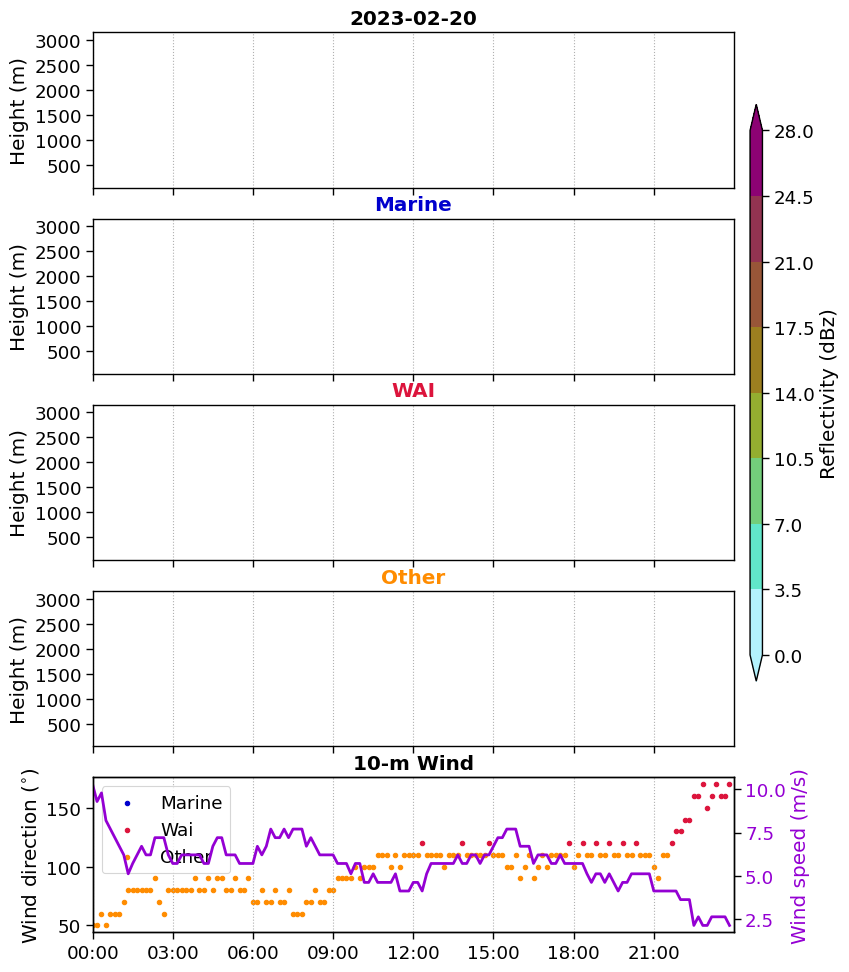

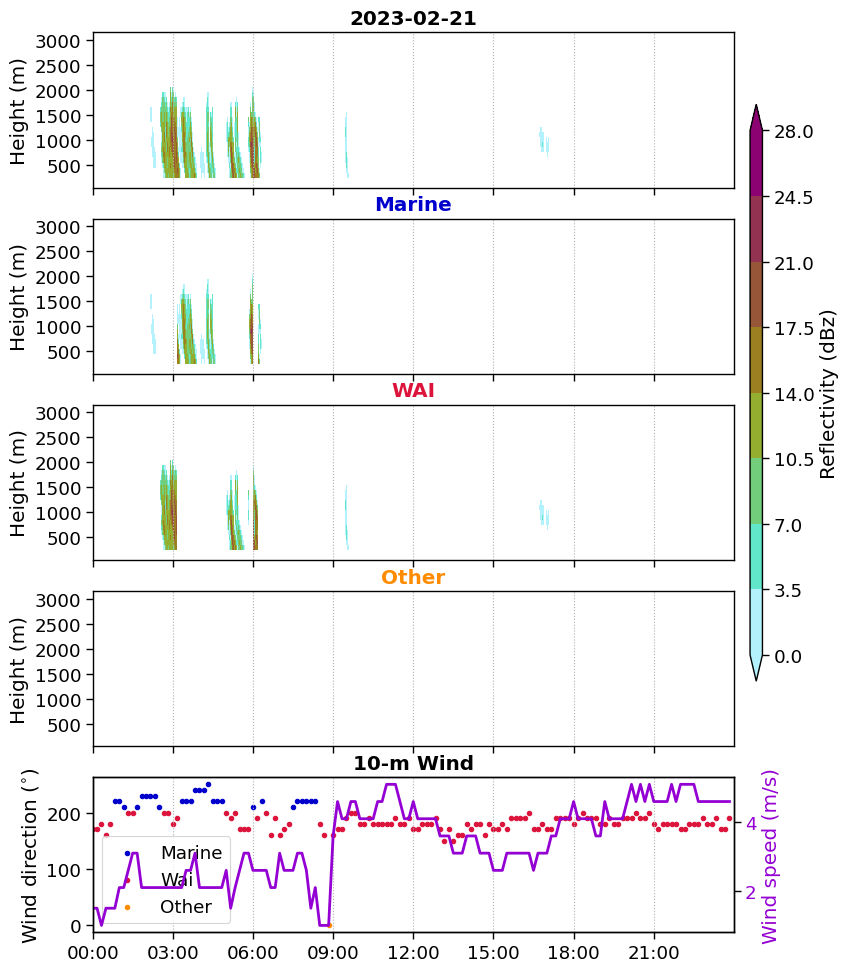

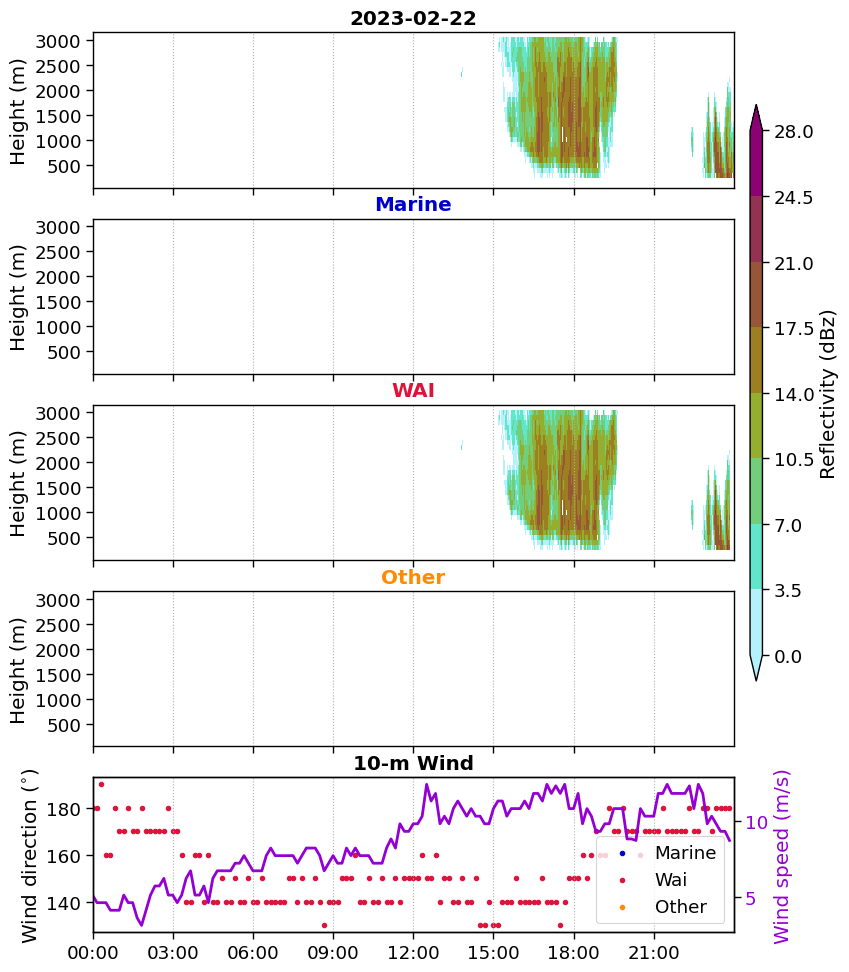

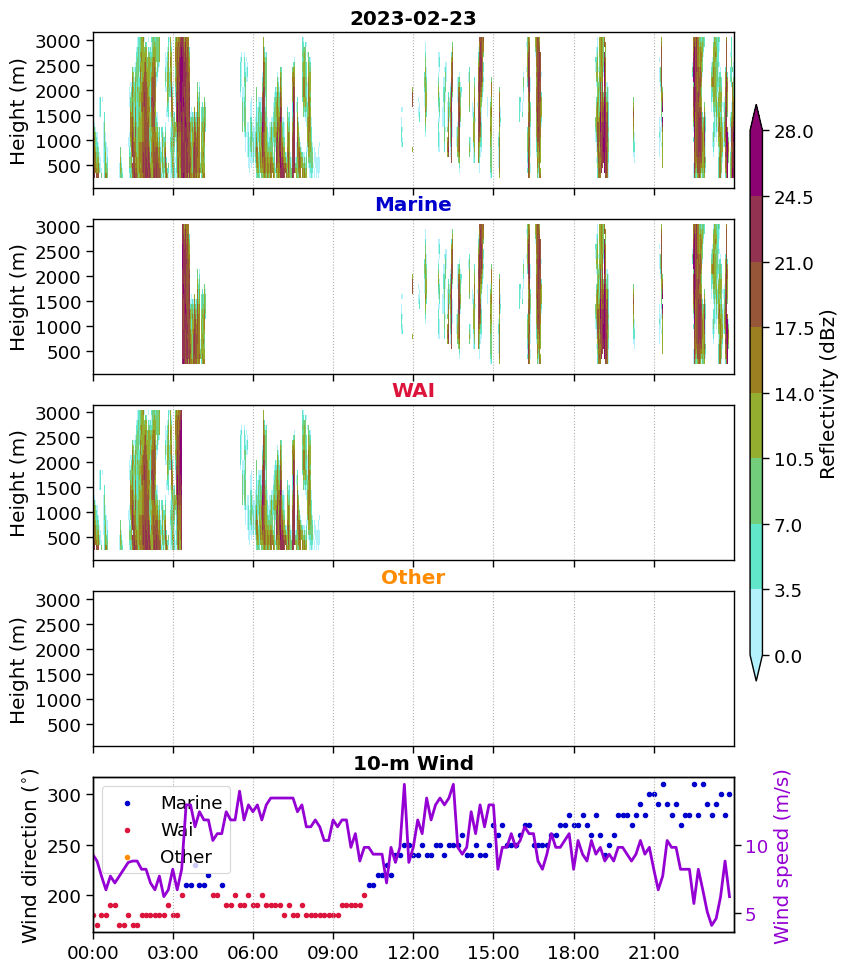

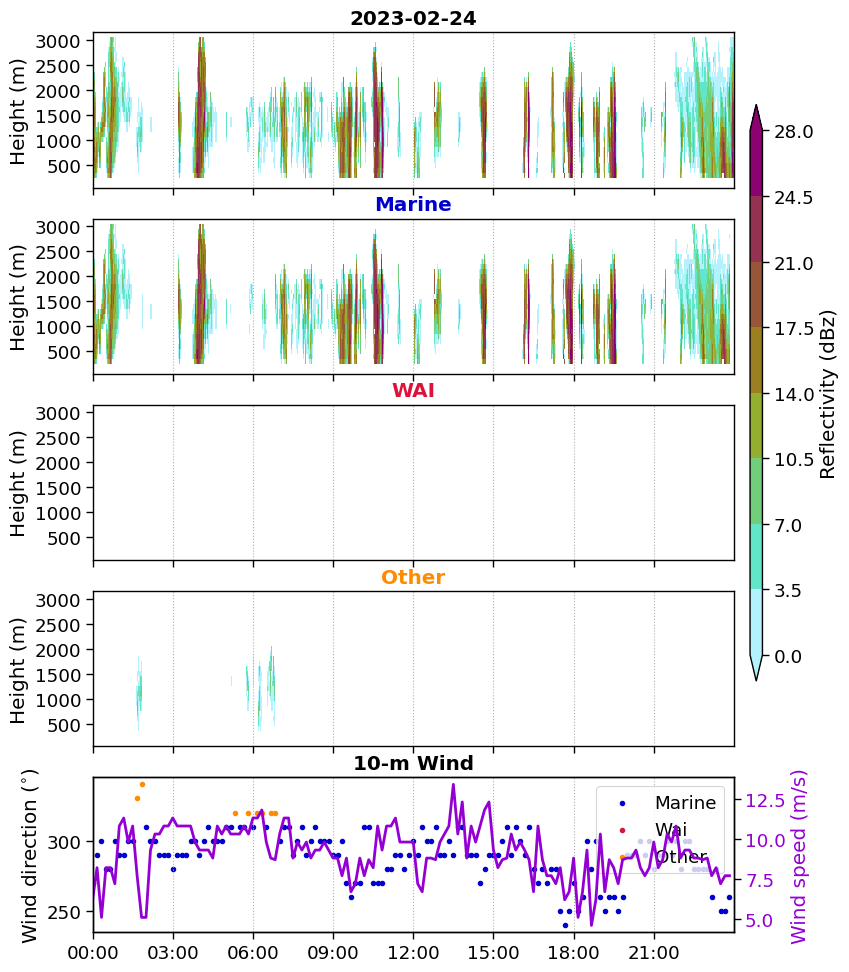

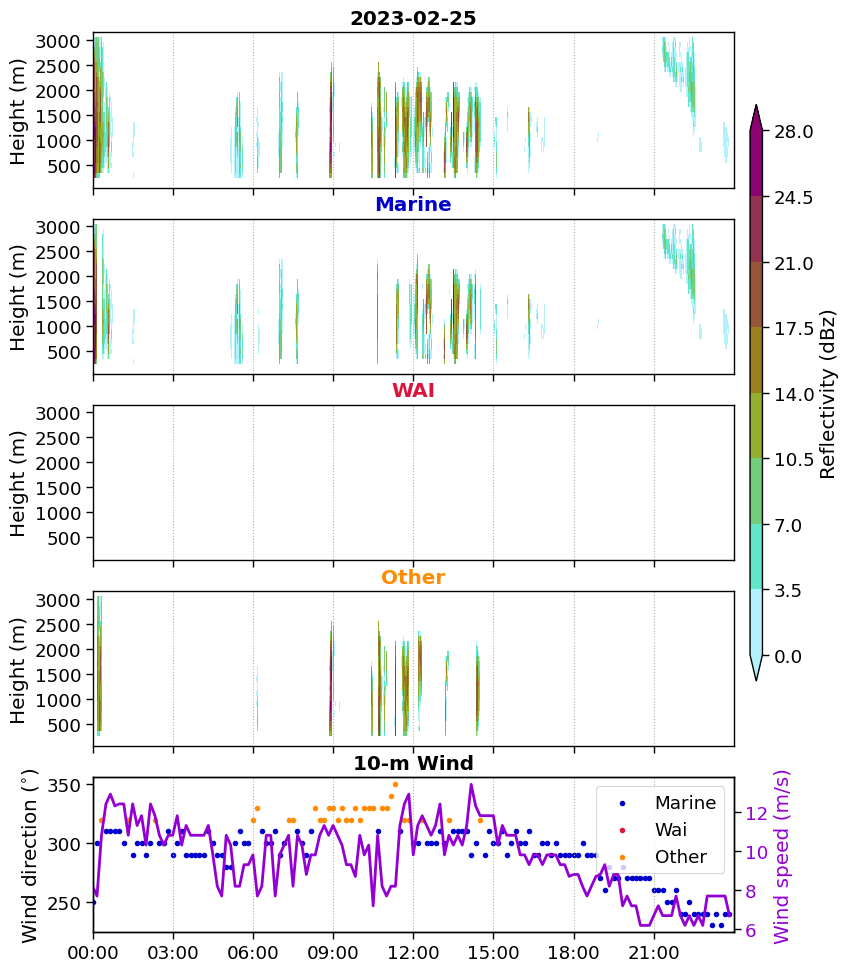

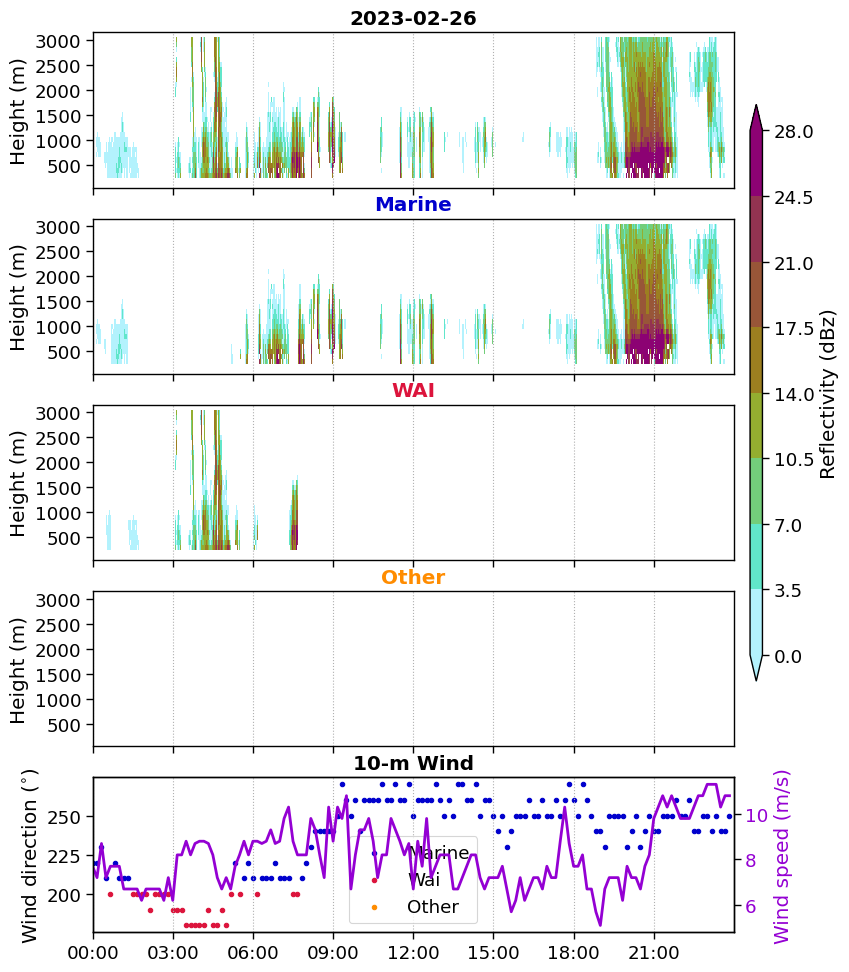

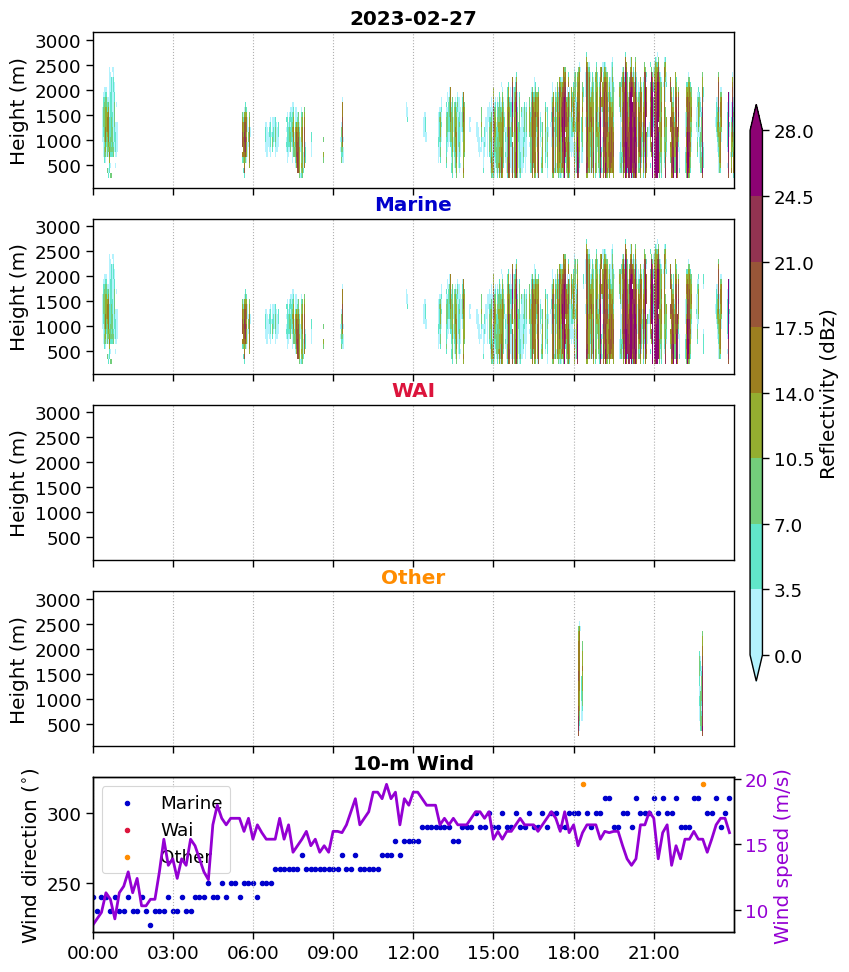

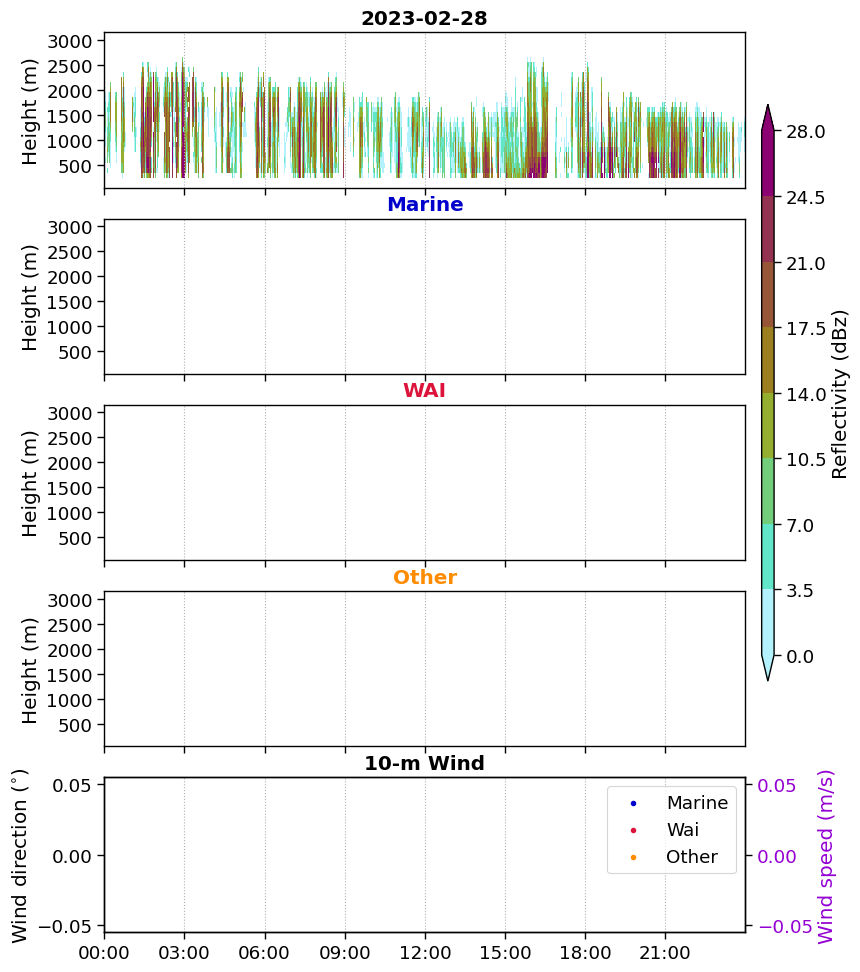

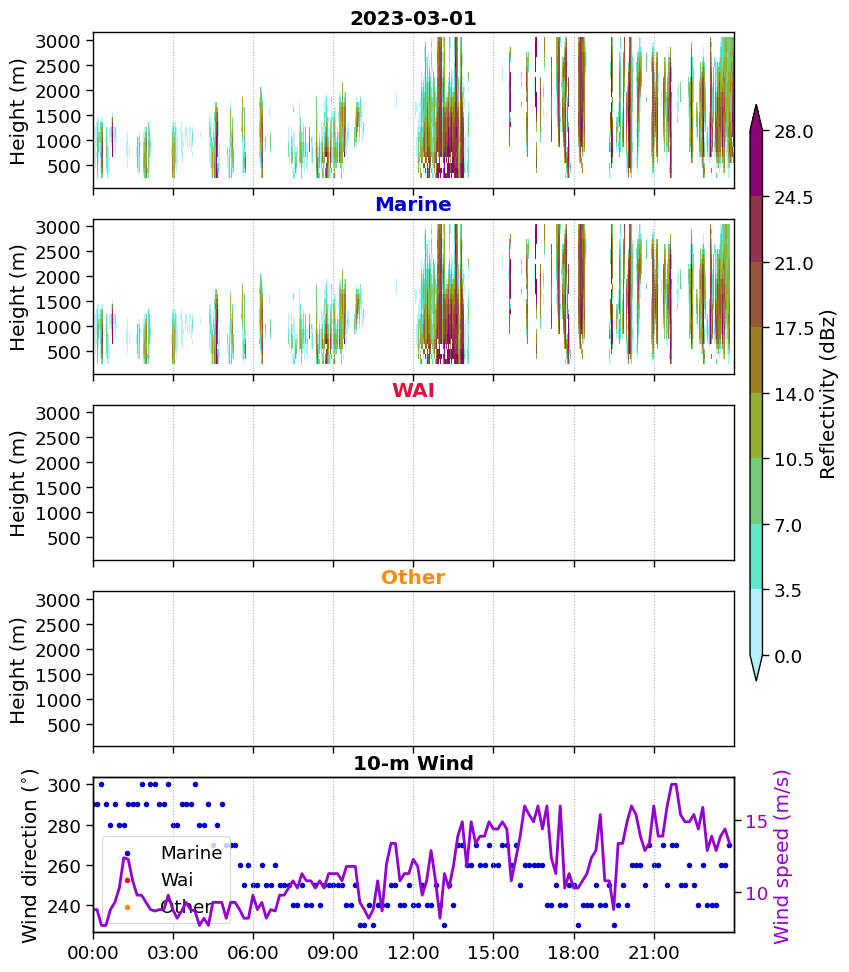

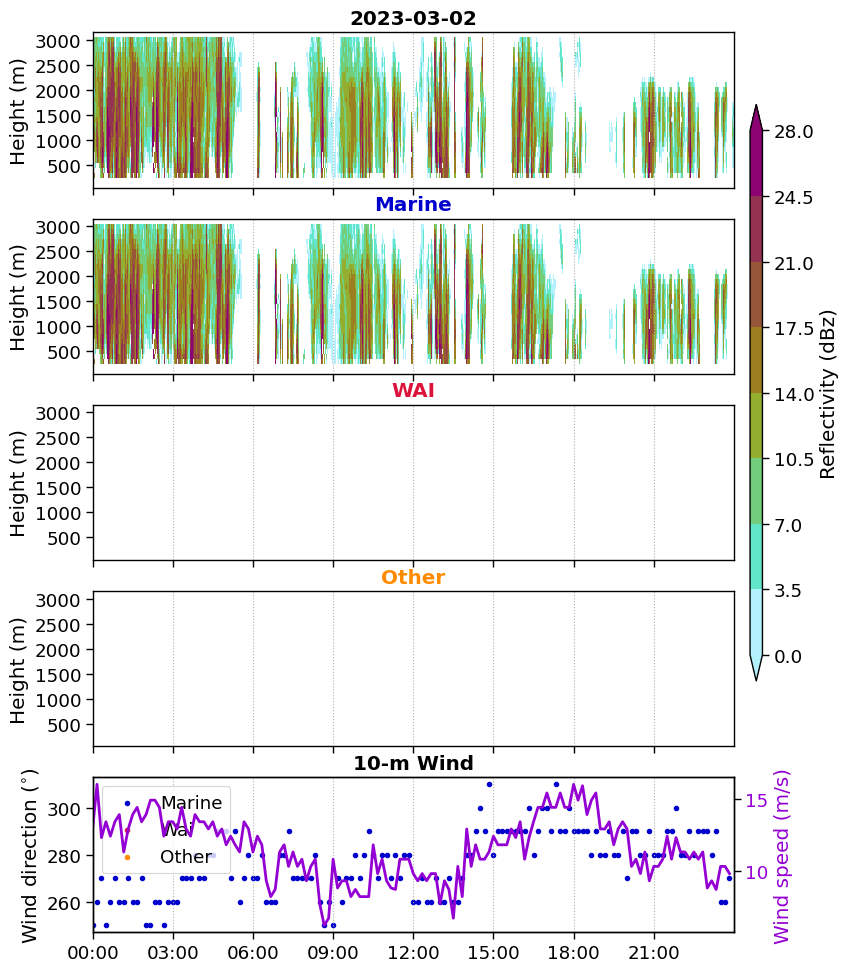

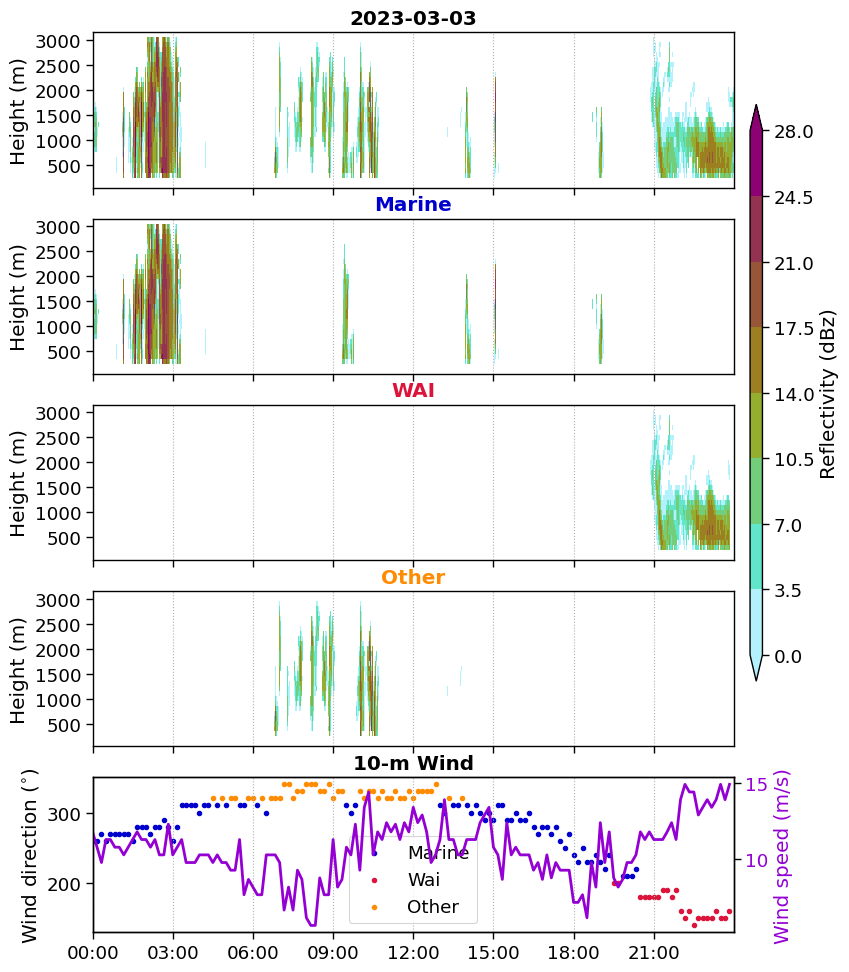

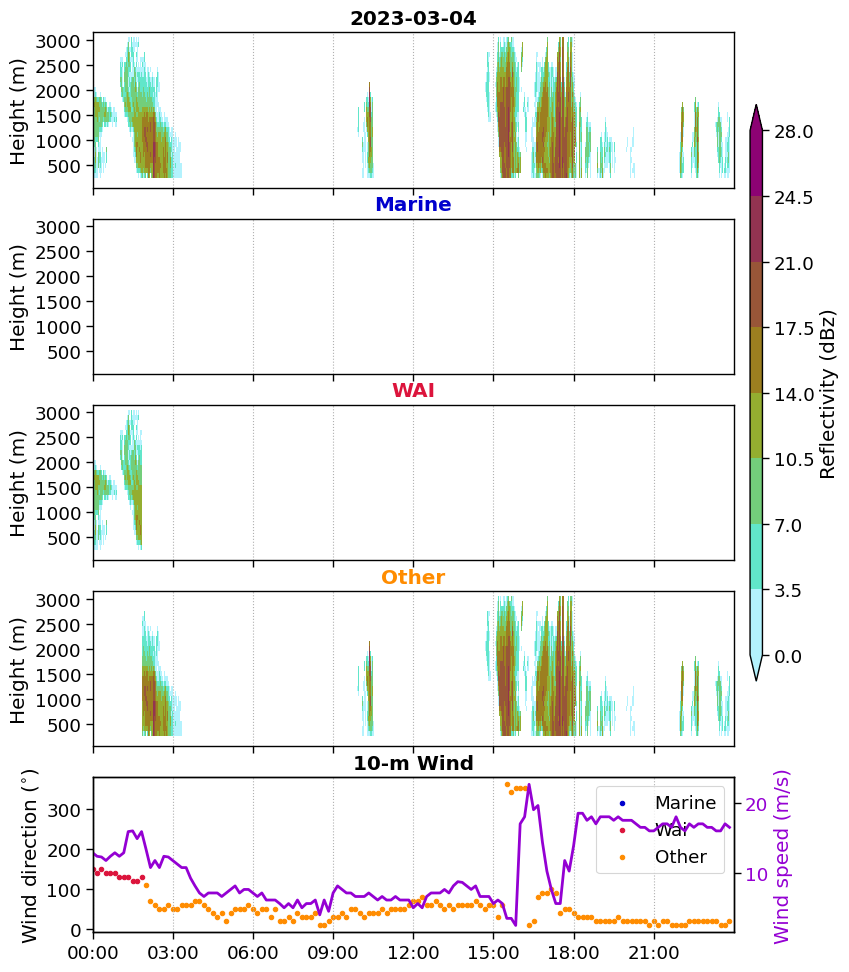

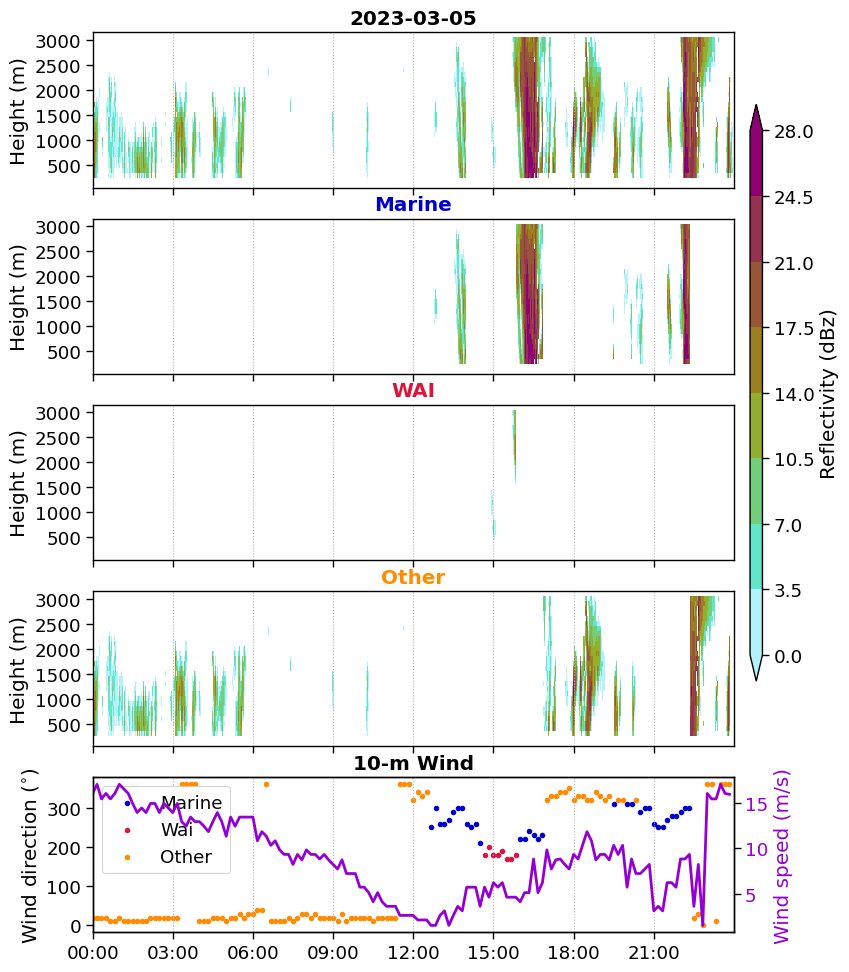

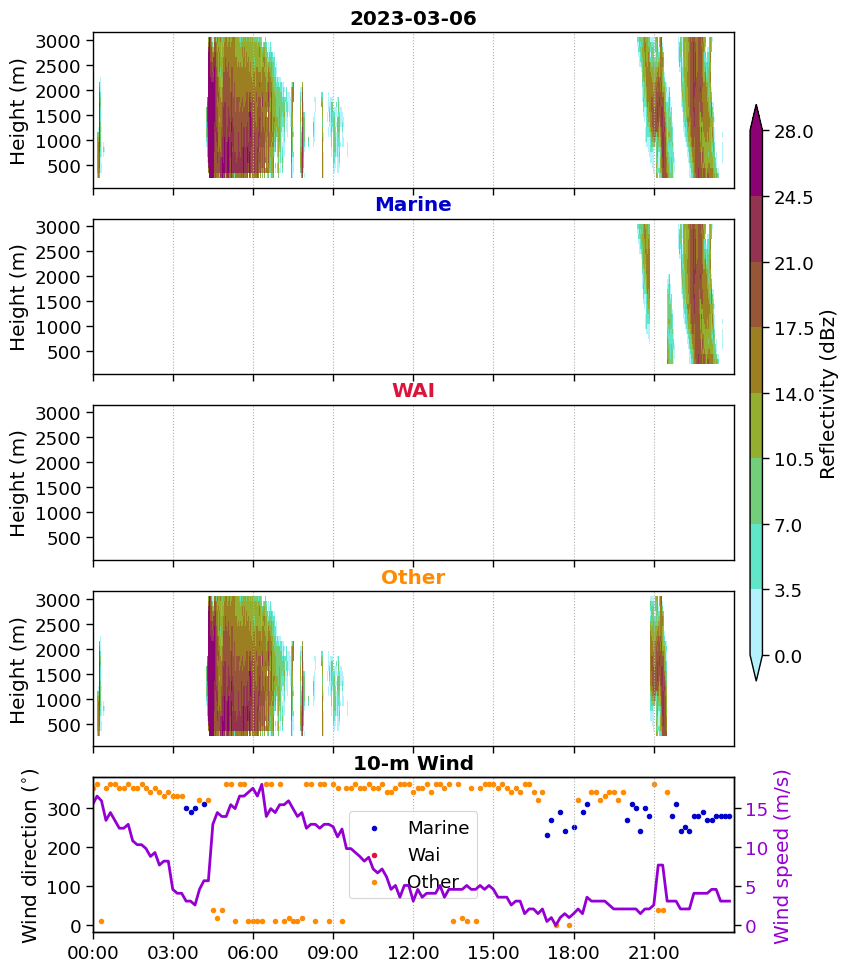

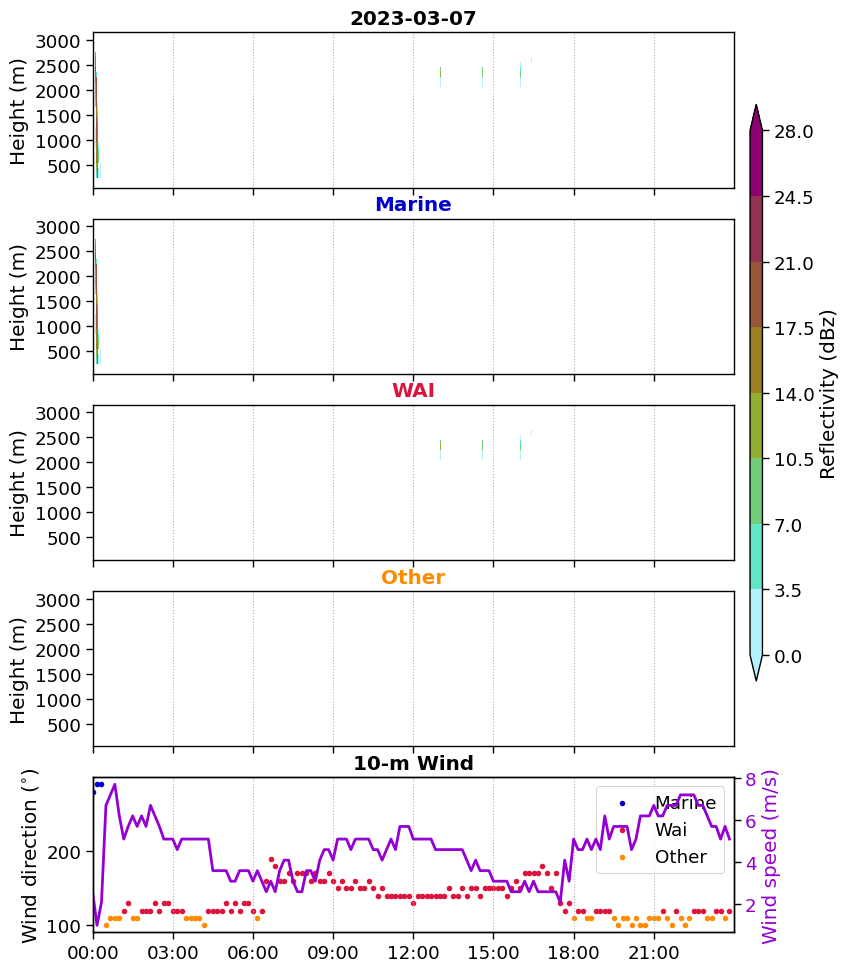

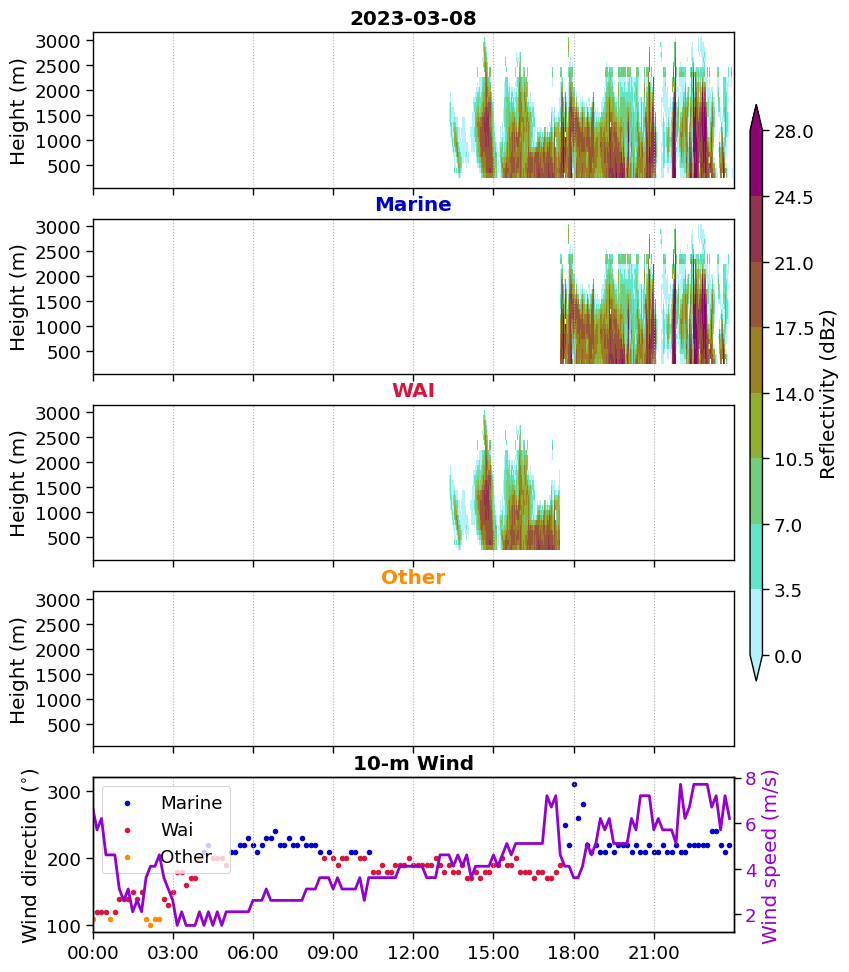

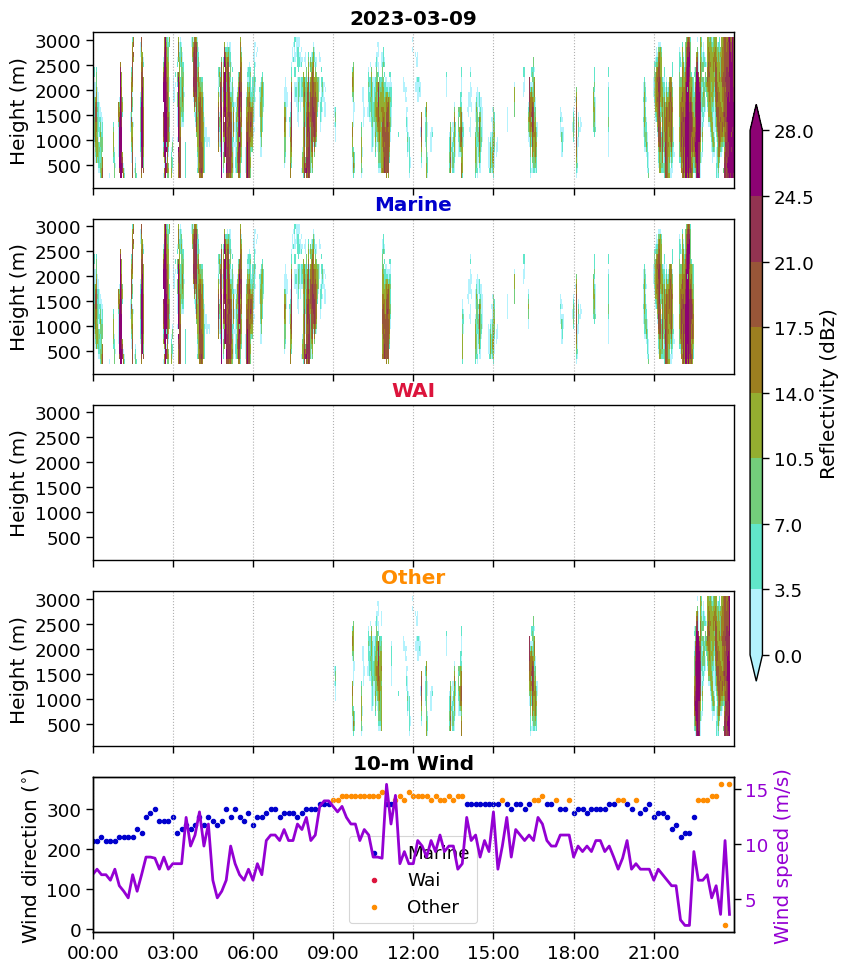

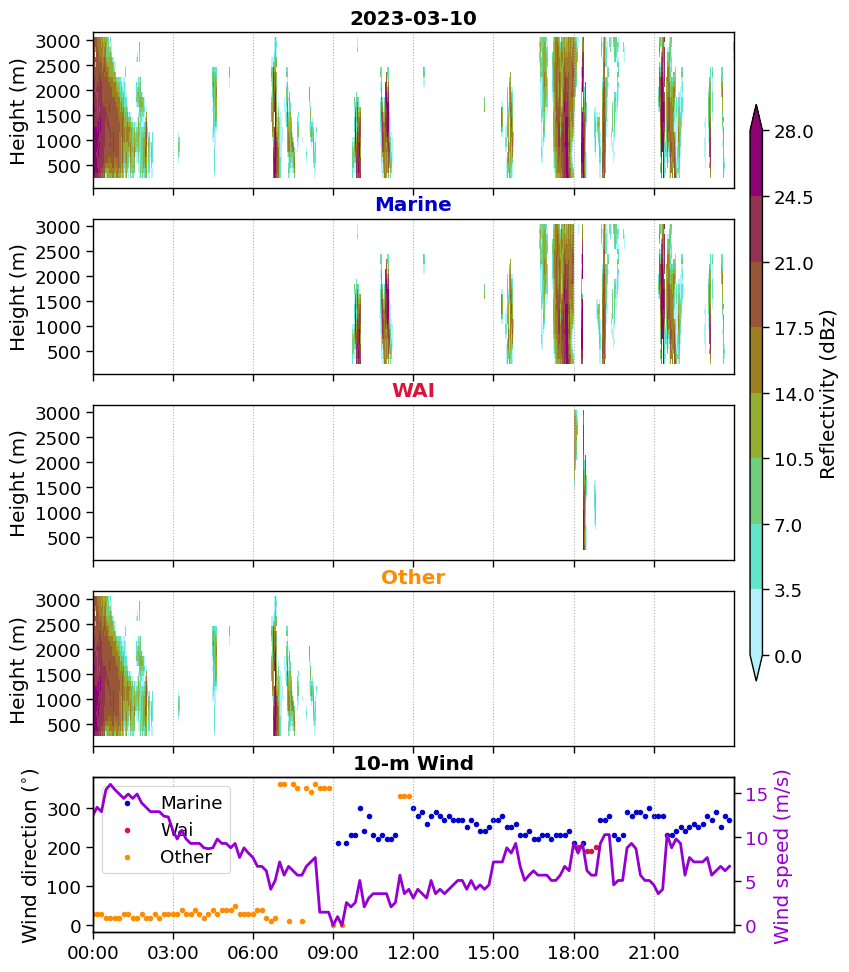

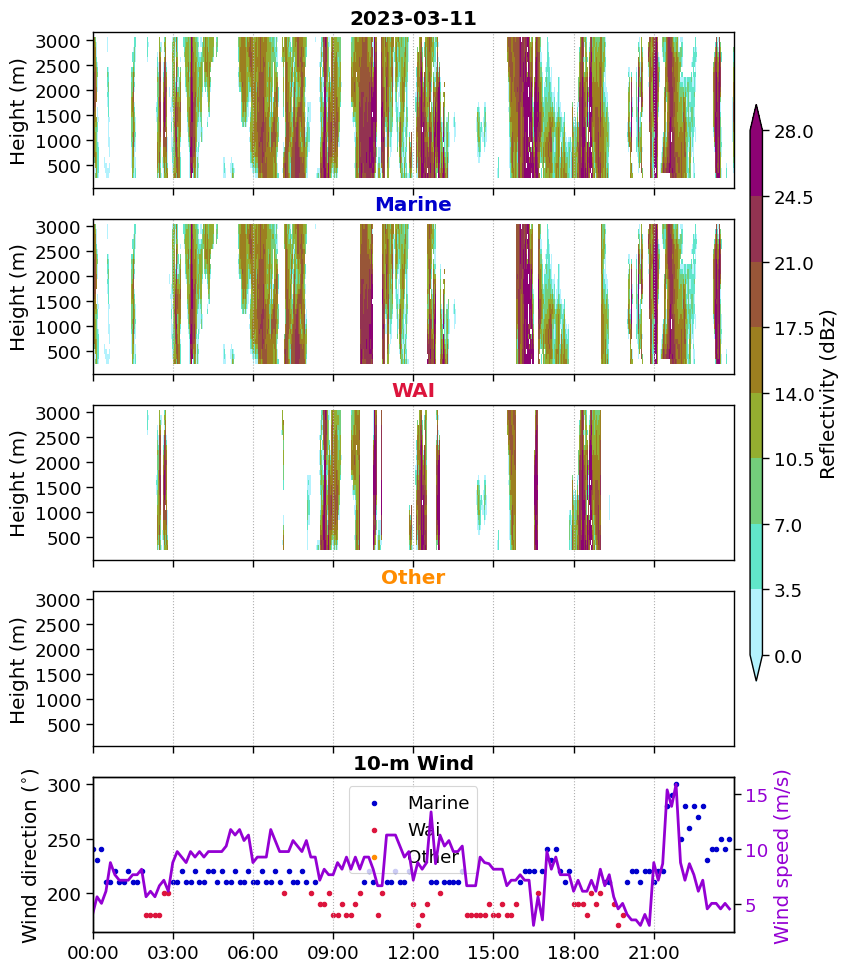

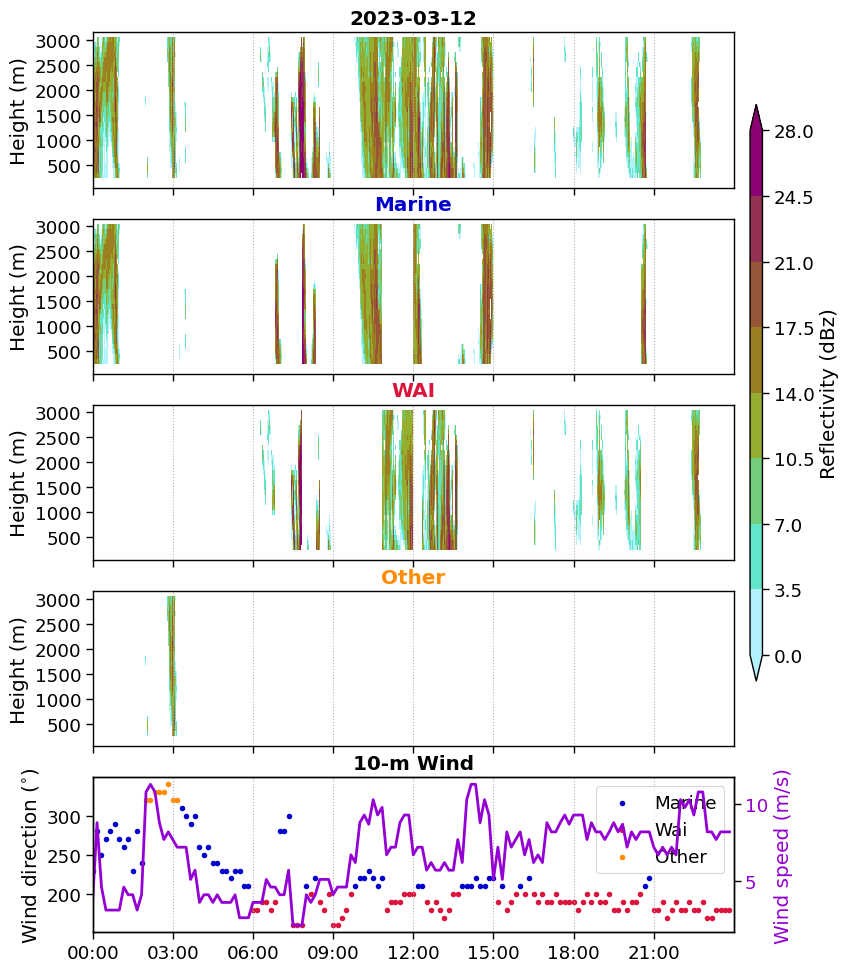

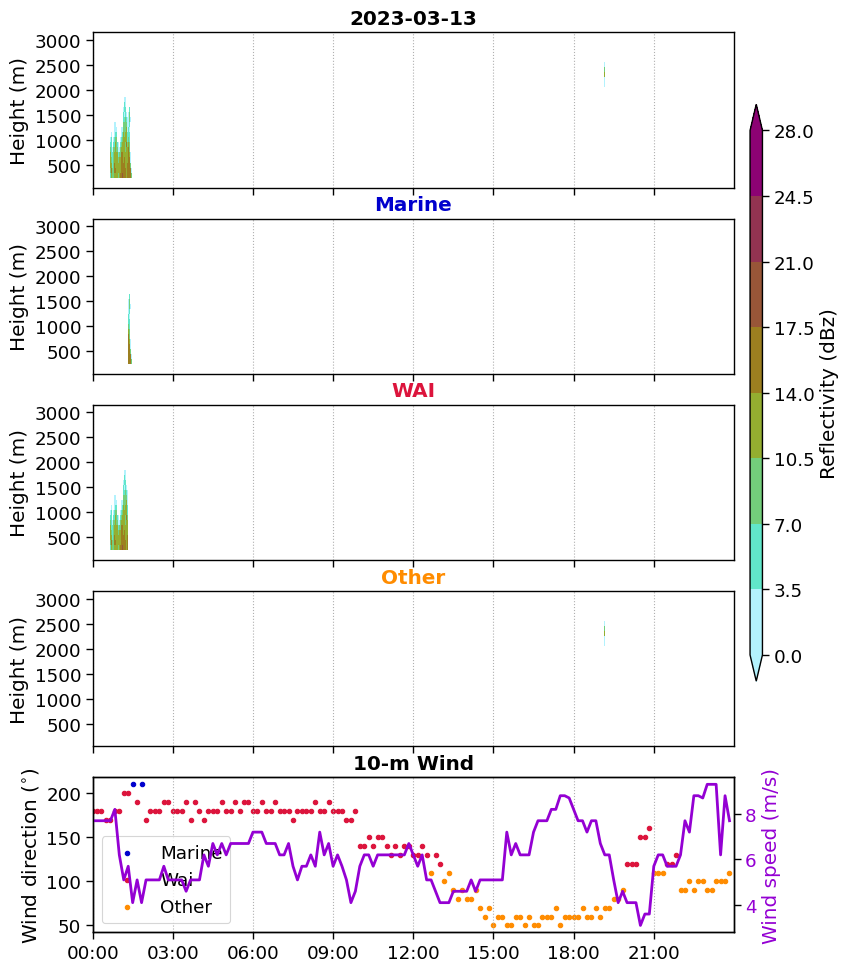

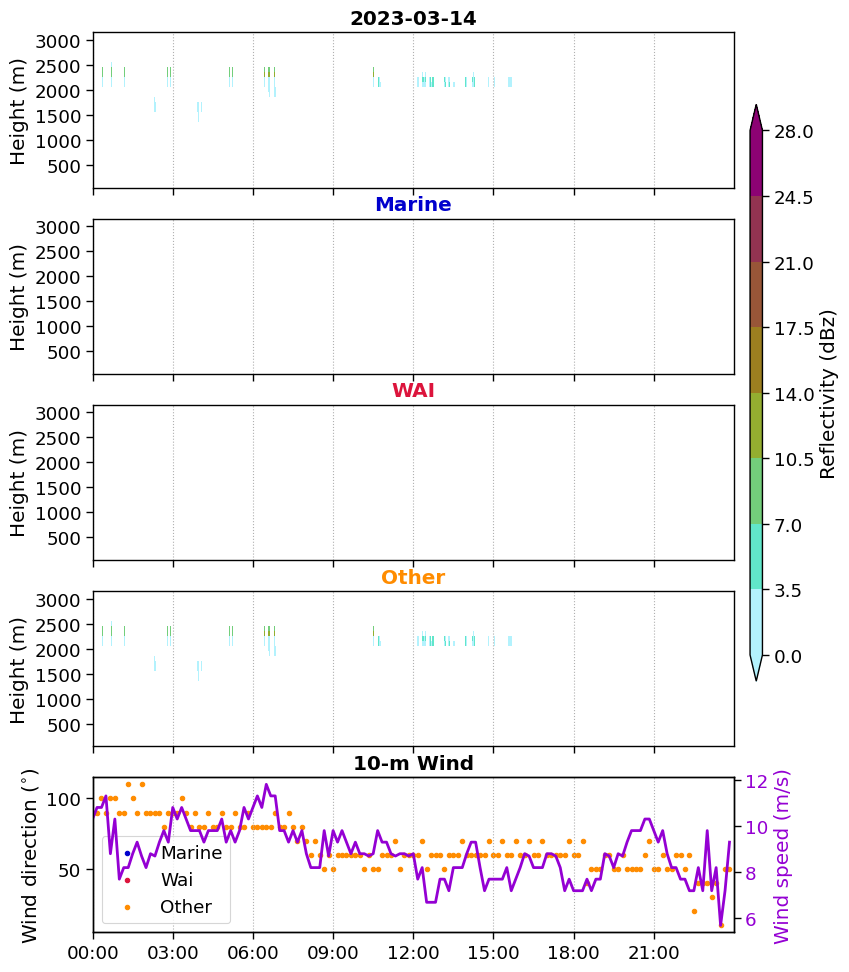

In [30]:
for date, day_ds in dsx.groupby('time.date'):
    plt_reflectivity_for_categories(day_ds)
    
    
    figname = f"ANX_obs_daily/mrr_reflectivity_WD_ANX_marine_WAI_other_{date}.png"
    plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
    